# Adult Census Income Classification

## End-to-End Machine Learning Pipeline

---

### Project Overview

The goal of this project is to build a machine learning classification system that predicts whether an individual's annual income exceeds $50,000 using demographic, education, and employment data from the 1994 U.S. Census (UCI Adult Dataset).

**Target Variable (`income`):**

- `0` (`<=50K`): Annual income less than or equal to $50,000.
- `1` (`>50K`): Annual income greater than $50,000.

### Dataset Description

- **Source:** UCI Machine Learning Repository
- **Size:** 32,561 rows and 15 columns, including the target.
- **Numerical Features:** `age`, `fnlwgt`, `education_num`, `capital_gain`, `capital_loss`, `hours_per_week`
- **Categorical Features:** `workclass`, `education`, `marital_status`, `occupation`, `relationship`, `race`, `sex`, `native_country`
- **Target:** `income`

### Project Workflow

1. **Exploratory Data Analysis (EDA):** Examine missing values, class distribution, feature distributions, outliers, and correlations.

2. **Data Splitting:** Divide the dataset into 80% training data and 20% hold-out test data using stratified sampling before fitting preprocessing steps.

3. **Feature Engineering and Preprocessing:** Create additional features and configure separate preprocessing pipelines for each model. Use One-Hot Encoding for XGBoost where required, native categorical feature handling for LightGBM and CatBoost where supported, and feature scaling for linear models.

4. **Hyperparameter Optimization:** Use Optuna with stratified K-fold cross-validation to select model parameters based on validation performance.

5. **Ensemble Models:** Train and compare Soft Voting, Blending, and Stacking classifiers using Logistic Regression as the meta-learner for the latter two approaches.

In [ ]:
import time
import warnings
warnings.filterwarnings('ignore')

# 1. Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Preprocessing, scaling, and data splitting
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder

# 3. Base estimators and ensemble models (Track A)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
    StackingClassifier
)

# 4. Gradient boosting frameworks (Track B)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from catboost import CatBoostClassifier, Pool

# 5. Hyperparameter tuning
import optuna

# 6. Evaluation metrics and model interpretability
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.inspection import permutation_importance

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

# The dataset does not have a header, so we should define the columns
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df = pd.read_csv(url, names=columns, skipinitialspace=True)

print(f"Data Shape: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
df.head()

Data Shape: 32,561 Rows | 15 Columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
# Remove extra whitespace from text columns
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# Replace '?' with missing values
df = df.replace("?", np.nan)

# Drop unnecessary columns
df = df.drop(columns=["education", "fnlwgt"], errors="ignore")

missing_summary = pd.DataFrame(
    {
        "Missing Count": df.isnull().sum(),
        "Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2),
    }
)

print(f"Data shape: {df.shape}")
print("\nMissing values:")
print(missing_summary[missing_summary["Missing Count"] > 0])

Data shape: (32561, 13)

Missing values:
                Missing Count  Percentage (%)
workclass                1836            5.64
occupation               1843            5.66
native-country            583            1.79


In [ ]:
for i in df.columns:
  print(df[i].value_counts())

age
36    898
31    888
34    886
23    877
35    876
     ... 
83      6
88      3
85      3
86      1
87      1
Name: count, Length: 73, dtype: int64
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
education-num
9     10501
10     7291
13     5355
14     1723
11     1382
7      1175
12     1067
6       933
4       646
15      576
5       514
8       433
16      413
3       333
2       168
1        51
Name: count, dtype: int64
marital-status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64
occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   education-num   32561 non-null  int64 
 3   marital-status  32561 non-null  object
 4   occupation      30718 non-null  object
 5   relationship    32561 non-null  object
 6   race            32561 non-null  object
 7   sex             32561 non-null  object
 8   capital-gain    32561 non-null  int64 
 9   capital-loss    32561 non-null  int64 
 10  hours-per-week  32561 non-null  int64 
 11  native-country  31978 non-null  object
 12  income          32561 non-null  object
dtypes: int64(5), object(8)
memory usage: 3.2+ MB


In [ ]:
df.describe()

,age,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,10.080679,1077.648844,87.303830,40.437456
std,13.640433,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.000000,0.000000,0.000000,1.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000
75%,48.000000,12.000000,0.000000,0.000000,45.000000
max,90.000000,16.000000,99999.000000,4356.000000,99.000000


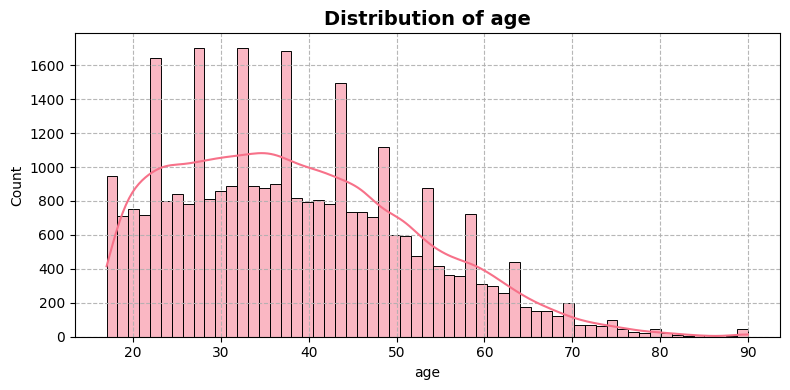

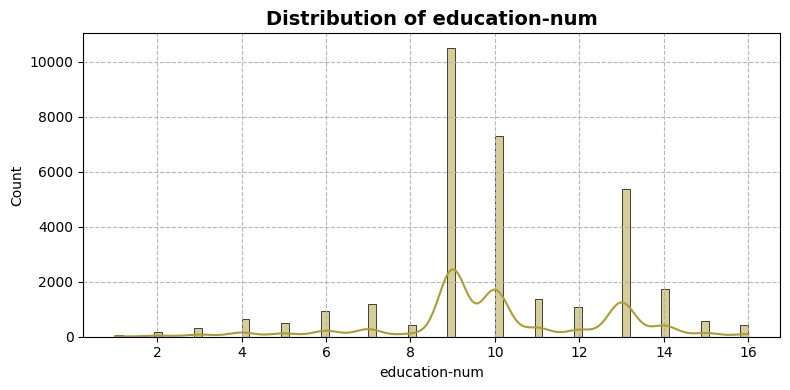

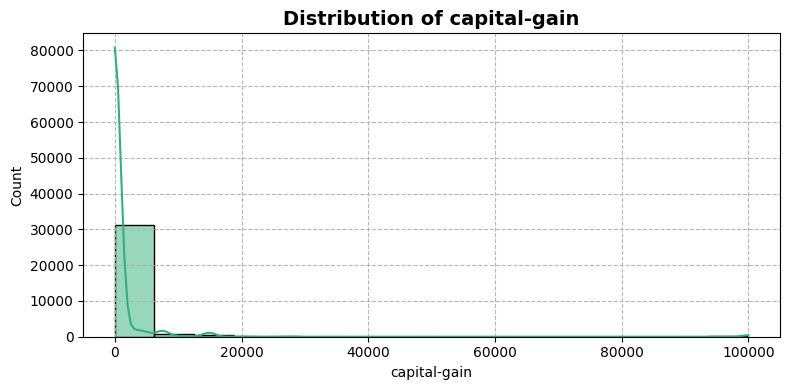

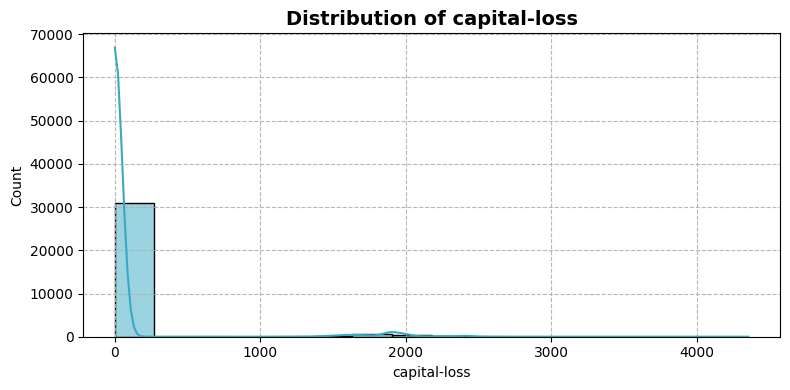

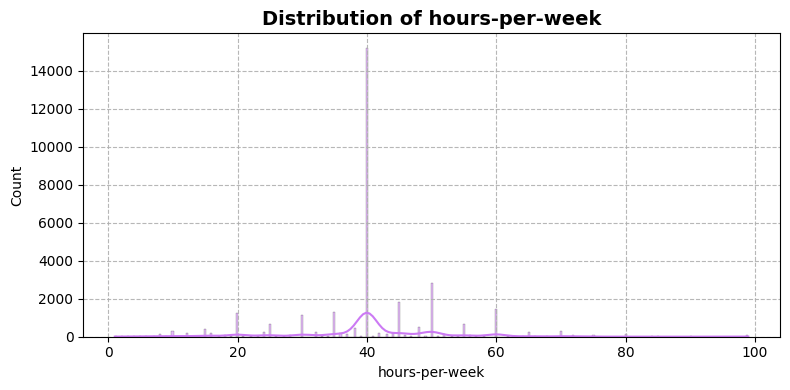

In [ ]:
palette = sns.color_palette("husl" , len(df.select_dtypes(include="number").columns))

for idx , col in enumerate(df.select_dtypes(include="number").columns):
  plt.figure(figsize=(8 , 4))
  sns.histplot(data=df , x=col , color=palette[idx] , edgecolor="black" , kde=True)
  plt.title(f"Distribution of {col}" , fontsize=14 , fontweight="bold")
  plt.grid(True , linestyle='--' , alpha=0.9)
  plt.tight_layout()
  plt.show()

In [ ]:
# Create a separate copy for EDA
df_eda = df.copy()

# Encode the target as binary values
df_eda["income"] = (
    df_eda["income"]
    .astype(str)
    .str.rstrip(".")
    .map({"<=50K": 0, ">50K": 1})
)

# Encode categorical columns while preserving missing values
cat_columns = df_eda.select_dtypes(include=["object"]).columns

for col in cat_columns:
    cat_series = df_eda[col].astype("category")
    df_eda[col] = cat_series.cat.codes.replace(-1, np.nan)

# Check the resulting data types
print(f"Data shape: {df_eda.shape}")
print("\nColumn data types:")
print(df_eda.dtypes)

df_eda.head()

Data shape: (32561, 13)

Column data types:
age                 int64
workclass         float64
education-num       int64
marital-status       int8
occupation        float64
relationship         int8
race                 int8
sex                  int8
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country    float64
income              int64
dtype: object


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,6.0,13,4,0.0,1,4,1,2174,0,40,38.0,0
1,50,5.0,13,2,3.0,0,4,1,0,0,13,38.0,0
2,38,3.0,9,0,5.0,1,4,1,0,0,40,38.0,0
3,53,3.0,7,2,5.0,0,2,1,0,0,40,38.0,0
4,28,3.0,13,2,9.0,5,2,0,0,0,40,4.0,0


/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


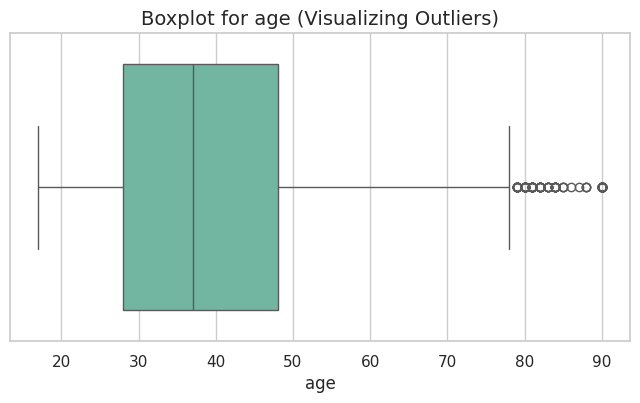

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


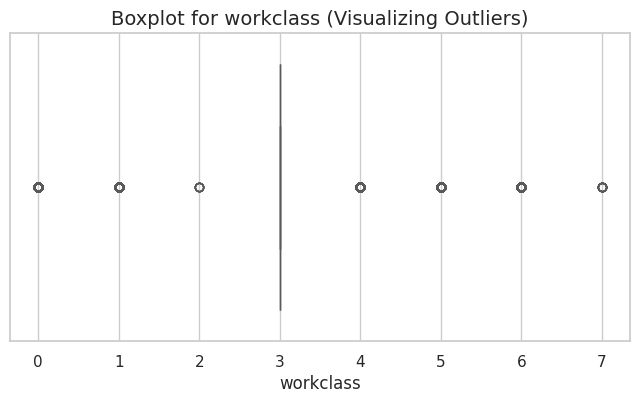

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


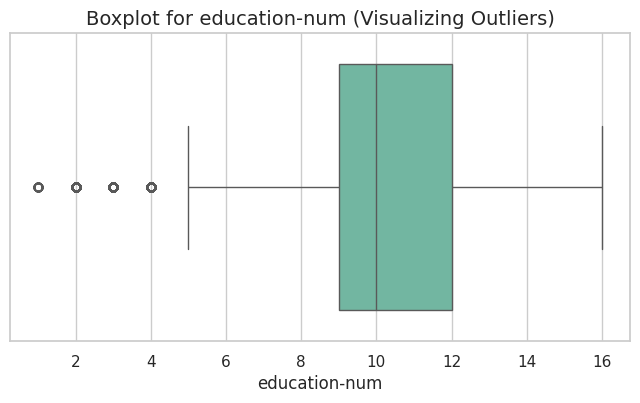

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


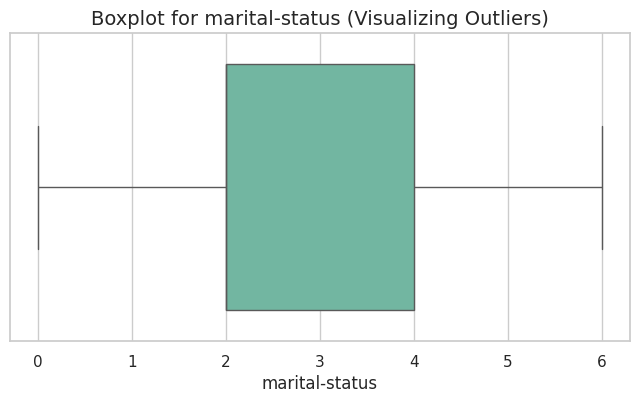

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


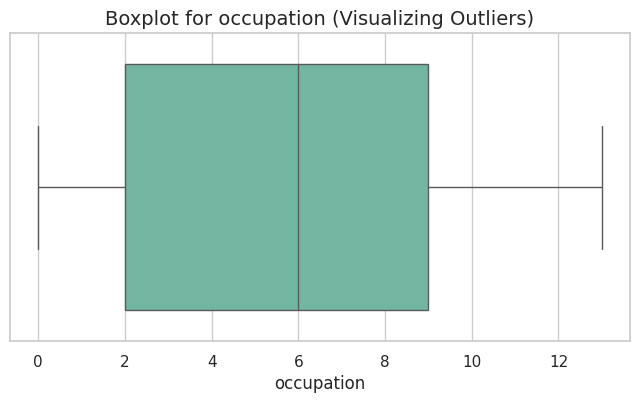

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


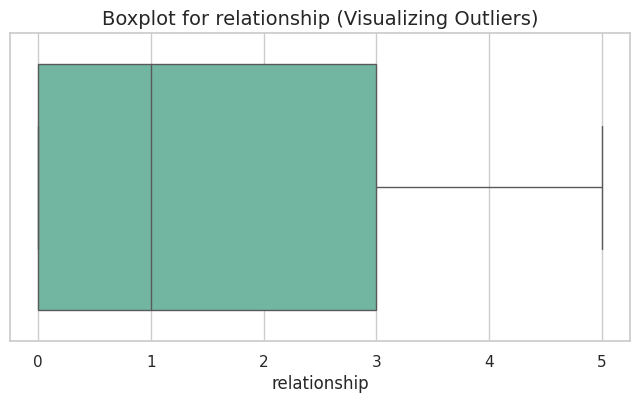

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


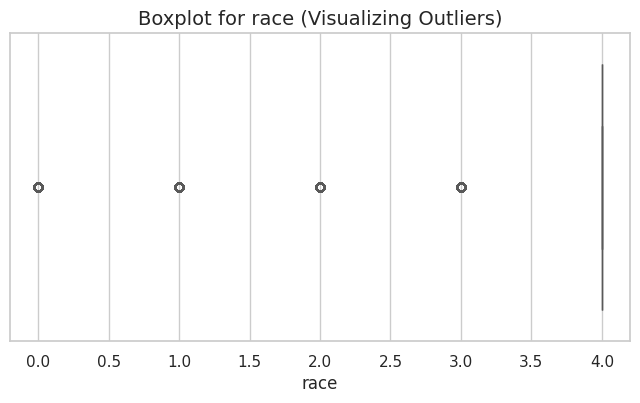

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


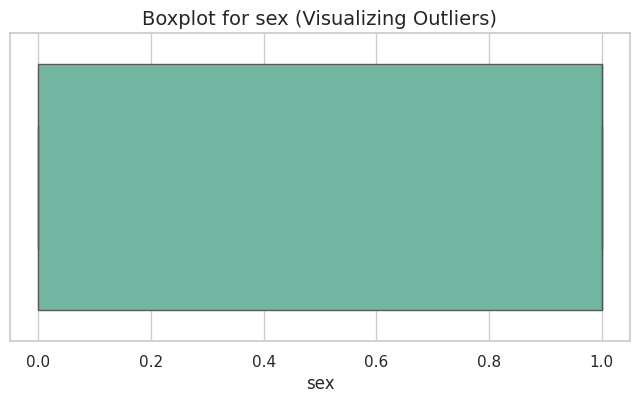

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


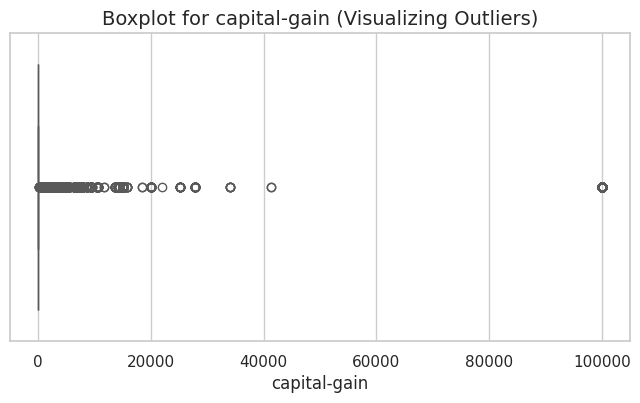

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


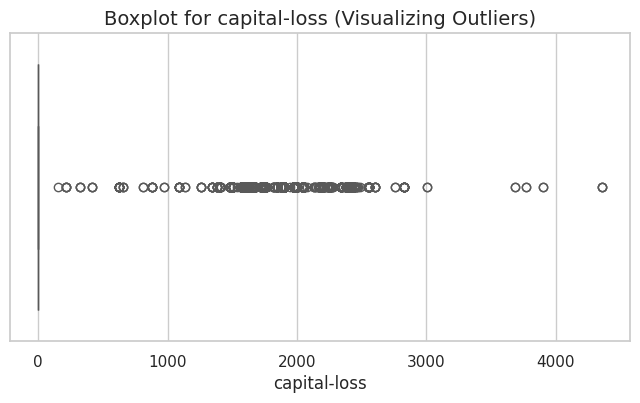

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


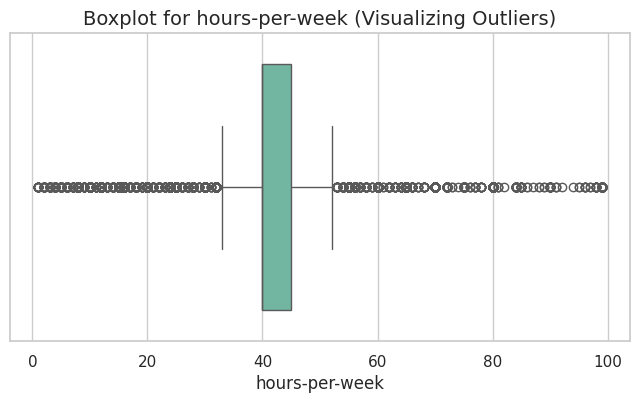

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


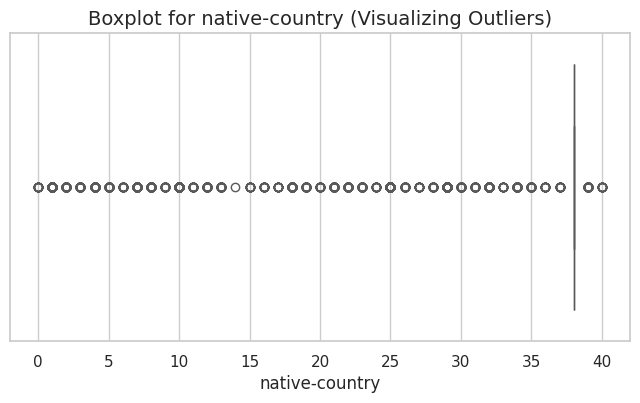

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


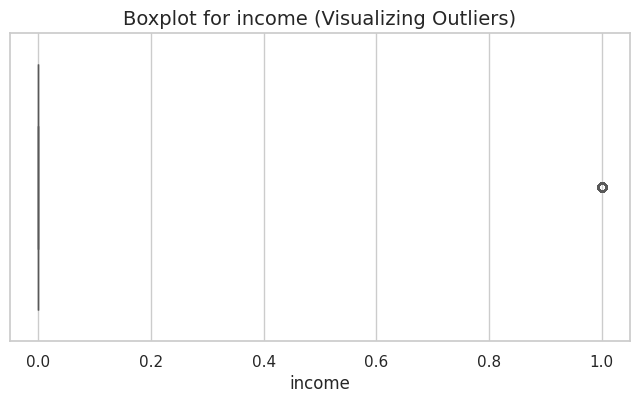

In [ ]:
for col in df_eda.columns:
  plt.figure(figsize=(8 , 4))
  sns.boxplot(data=df_eda , x=col , palette="Set2")
  plt.title(f"Boxplot for {col} (Visualizing Outliers)" , fontsize=14)
  plt.show()

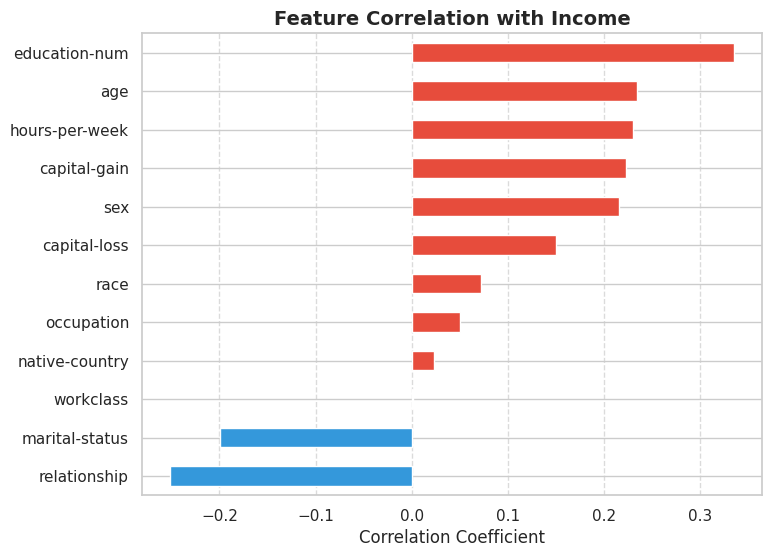

In [ ]:
income_corr = df_eda.corr()['income'].drop('income').sort_values(ascending=True)

plt.figure(figsize=(8, 6))
income_corr.plot(kind='barh', color=income_corr.map(lambda x: '#e74c3c' if x > 0 else '#3498db'))
plt.title("Feature Correlation with Income", fontsize=14, fontweight='bold')
plt.xlabel("Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Exploratory Data Analysis: Findings and Feature Engineering Decisions

---

### 1. Data Cleaning and Feature Selection

- Converted missing values represented by `?` into `np.nan` across the dataset.
- Removed `education` because it represents the same educational attainment information as `education_num`, which provides a numerical representation of education level.
- Removed `fnlwgt` because it represents the final sampling weight used in the census dataset rather than a direct individual attribute.

### 2. Missing Values Analysis

Missing values were found in three categorical features:

| Feature | Missing Values | Percentage |
|:---|---:|---:|
| `occupation` | 1,843 | 5.66% |
| `workclass` | 1,836 | 5.64% |
| `native-country` | 583 | 1.79% |

The numerical features contained no missing values.

**Decision:** Missing categorical values will be imputed using the most frequent category calculated from the training set. Imputation will be performed after the train-test split to prevent data leakage.

### 3. Class Distribution

The target variable contains two classes:

| Income Class | Number of Samples | Percentage |
|:---|---:|---:|
| `<=50K` | 24,720 | 75.92% |
| `>50K` | 7,841 | 24.08% |

The ratio between the majority and minority classes is approximately 3.15:1.

**Modeling decisions:**

- Use ROC-AUC, PR-AUC, and F1-Score to evaluate model performance rather than relying on accuracy alone.
- Use stratified splitting and `StratifiedKFold` to preserve class proportions.
- Evaluate class weighting in boosting models where supported, using validation results to select appropriate values.

### 4. Numerical Distributions and Outliers

- **Capital Features:** `capital_gain` contains approximately 91.6% zero values, while `capital_loss` contains approximately 95.3%. Both features are strongly right-skewed, with observed values reaching 99,999.
- **Working Hours:** `hours_per_week` has a mean of 40.43 hours and a standard deviation of 12.35. Most observations are concentrated around a standard working week, with variation in part-time and longer working hours.
- **Age:** Ages range from 17 to 90 years, with a median of 37 years and a moderately right-skewed distribution.

**Decision:** Outliers will not be removed solely because they fall outside conventional statistical limits. Tree-based models will be evaluated using the original numerical values, while additional features will capture relevant information such as capital activity.

### 5. Correlation and Categorical Patterns

#### Numerical Features

The strongest reported linear correlations with the income target were:

| Feature | Correlation with Income |
|:---|---:|
| `education_num` | +0.34 |
| `age` | +0.23 |
| `hours_per_week` | +0.23 |
| `capital_gain` | +0.22 |

These correlations provide an initial view of the relationship between numerical features and income. They do not capture all nonlinear relationships or interactions between variables.

#### Categorical Features

- **`marital_status`:** The `Married-civ-spouse` category has a higher proportion of individuals earning above $50K than several unmarried categories.
- **`native_country`:** The feature contains 41 distinct countries, with `United-States` accounting for approximately 89.58% of observations.

### 6. Feature Engineering Plan

#### Capital Features

- `capital_net` = `capital_gain - capital_loss`
- `has_capital_gain` = `1` if `capital_gain > 0`, otherwise `0`.
- `has_capital_loss` = `1` if `capital_loss > 0`, otherwise `0`.

#### Categorical Features

- **`native_country`:** Create a binary feature distinguishing `United-States` from other recorded countries.
- **`marital_status`:** Group categories into broader married and unmarried groups using a consistent mapping.

These transformations are intended to simplify selected features while preserving information relevant to income prediction.

---

### Next Phase: Data Splitting and Model Pipelines

The dataset will be divided into an 80% training set and a 20% hold-out test set using stratified sampling. Separate preprocessing pipelines will then be prepared for XGBoost, LightGBM, and CatBoost, with preprocessing parameters fitted using training data only.

In [ ]:
from sklearn.model_selection import train_test_split

df['income'] = df['income'].astype(str).str.rstrip('.').map({'<=50K': 0, '>50K': 1})

X = df.drop('income', axis=1)
y = df['income']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Training set: {X_train.shape}, Target: {y_train.shape}")
print(f"Test set: {X_test.shape}, Target: {y_test.shape}")
print(f"\nTraining target distribution:\n{y_train.value_counts(normalize=True).round(4)}")

Training set: (26048, 12), Target: (26048,)
Test set: (6513, 12), Target: (6513,)

Training target distribution:
income
0    0.7592
1    0.2408
Name: proportion, dtype: float64


In [ ]:
missing_cat_cols = ['workclass', 'occupation', 'native-country']

# Calculate modes using the training set
train_modes = {col: X_train[col].mode()[0] for col in missing_cat_cols}
print("Training set modes:")
for col, mode_val in train_modes.items():
    print(f"{col}: {mode_val}")

# Fill missing values in both sets using the training modes
for col, mode_val in train_modes.items():
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col] = X_test[col].fillna(mode_val)

print(f"\nMissing values in X_train: {X_train.isnull().sum().sum()}")
print(f"Missing values in X_test: {X_test.isnull().sum().sum()}")

Training set modes:
workclass: Private
occupation: Prof-specialty
native-country: United-States

Missing values in X_train: 0
Missing values in X_test: 0


In [ ]:
def engineer_features(data):
    df_feat = data.copy()

    # Net capital and investment indicators
    df_feat['capital_net'] = df_feat['capital-gain'] - df_feat['capital-loss']
    df_feat['has_capital_gain'] = (df_feat['capital-gain'] > 0).astype(int)
    df_feat['has_capital_loss'] = (df_feat['capital-loss'] > 0).astype(int)

    # Simplify country and marital status
    df_feat['is_native_us'] = (df_feat['native-country'] == 'United-States').astype(int)
    married_categories = ['Married-civ-spouse', 'Married-AF-spouse']
    df_feat['is_married'] = df_feat['marital-status'].isin(married_categories).astype(int)

    # Identify overtime hours
    df_feat['is_overtime'] = (df_feat['hours-per-week'] > 40).astype(int)

    return df_feat

X_train = engineer_features(X_train)
X_test = engineer_features(X_test)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train[['capital_net', 'has_capital_gain', 'is_native_us', 'is_married', 'is_overtime']].head()

X_train shape: (26048, 18)
X_test shape: (6513, 18)


,capital_net,has_capital_gain,is_native_us,is_married,is_overtime
0,0,0,1,1,1
1,0,0,1,0,1
2,0,0,1,0,0
3,6849,1,1,0,0
4,0,0,1,0,0


In [ ]:
# Apply log1p to skewed features
skewed_cols = ['capital-gain', 'capital-loss']

for col in skewed_cols:
    X_train[f'{col}_log'] = np.log1p(X_train[col])
    X_test[f'{col}_log'] = np.log1p(X_test[col])

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train[[f'{col}_log' for col in skewed_cols]].describe().T[
    ['min', 'mean', '50%', 'max']
].round(2)

X_train shape: (26048, 20)
X_test shape: (6513, 20)


,min,mean,50%,max
capital-gain_log,0.0,0.73,0.0,11.51
capital-loss_log,0.0,0.35,0.0,8.38


In [ ]:
# Check feature types and dataset consistency
print(f"Total features: {X_train.shape[1]}")
print(f"Numerical features: {len(X_train.select_dtypes(include=['number']).columns)}")
print(f"Categorical features: {len(X_train.select_dtypes(include=['object', 'category']).columns)}")
print(f"Categorical columns: {X_train.select_dtypes(include=['object', 'category']).columns.tolist()}")

# Check for missing values
assert X_train.isnull().sum().sum() == 0, "Missing values found in X_train"
assert X_test.isnull().sum().sum() == 0, "Missing values found in X_test"

print("\nNo missing values found in either dataset.")

Total features: 20
Numerical features: 13
Categorical features: 7
Categorical columns: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

No missing values found in either dataset.


In [ ]:
from sklearn.model_selection import StratifiedKFold

# Clean feature names
X_train.columns = X_train.columns.str.replace('-', '_')
X_test.columns = X_test.columns.str.replace('-', '_')

# Separate categorical and numerical features
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()

print(f"Categorical features ({len(cat_cols)}): {cat_cols}")
print(f"Numerical features ({len(num_cols)}): {num_cols}")

# Calculate class imbalance ratio
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"\nScale positive weight: {scale_pos_weight:.2f}")

# Set up stratified 5-fold cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("5-fold stratified cross-validation initialized.")

Categorical features (7): ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Numerical features (13): ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_native_us', 'is_married', 'is_overtime', 'capital_gain_log', 'capital_loss_log']

Scale positive weight: 3.15
5-fold stratified cross-validation initialized.


# Data Preprocessing and Feature Engineering Summary

---

### 1. Data Splitting and Leakage Prevention

- **Target Encoding:** Converted `income` into a binary variable (`0` for `<=50K` and `1` for `>50K`).
- **Stratified Split:** Split the dataset into 80% training data and 20% test data using `train_test_split`, with `stratify=y` and `random_state=42`.
- **Data Integrity:** Reset the indices of both partitions. Statistical parameters used in preprocessing were calculated from the training set and then applied to the test set where appropriate.

### 2. Missing Value Imputation

- Checked the categorical features `workclass`, `occupation`, and `native_country` for missing values.
- Filled missing values using the most frequent category calculated from `X_train`.
- Applied the same imputation values to `X_train` and `X_test`.
- Verified that no missing values remained after imputation.

### 3. Feature Engineering

The following features were created for both the training and test sets:

- **Net Capital (`capital_net`):** Calculated as `capital_gain - capital_loss` to represent the difference between capital gains and losses.
- **Capital Activity Indicators (`has_capital_gain`, `has_capital_loss`):** Binary features indicating whether capital gains or losses are greater than zero.
- **Marital Status (`is_married`):** Combined the relevant married categories into a binary indicator distinguishing married from unmarried individuals.
- **Geographic Indicator (`is_native_us`):** Created a binary feature distinguishing individuals whose recorded native country is the United States from those with another recorded country.
- **Overtime Indicator (`is_overtime`):** Set to `1` when `hours_per_week > 40` and `0` otherwise.

### 4. Log Transformations

Applied `np.log1p` to the capital gain and capital loss features to reduce the effect of their right-skewed distributions.

- `capital_gain_log = np.log1p(capital_gain)`
- `capital_loss_log = np.log1p(capital_loss)`

These transformations were applied to non-negative features. The original capital values were retained for use in other engineered features, including `capital_net`.

### 5. Feature Preparation and Validation

- **Feature Names:** Replaced hyphens with underscores in feature names to maintain consistent naming across preprocessing and modeling pipelines.
- **Feature Groups:** Organized features into `cat_cols` for categorical variables and `num_cols` for numerical variables and binary indicators.
- **Class Weighting:** Calculated the positive-to-negative class ratio from `y_train`, approximately 3.15:1, for use in the boosting models where applicable.
- **Cross-Validation:** Configured `StratifiedKFold` with five splits, `shuffle=True`, and `random_state=42`. The same fold configuration was used across model optimization and evaluation workflows, including the generation of out-of-fold predictions for stacking.

# Modeling Strategy: Benchmarking and Hyperparameter Optimization

---

### 1. Modeling Strategy

The modeling phase is divided into two tracks to compare ensemble methods and gradient boosting frameworks under consistent evaluation conditions.

Each architecture uses a dedicated pipeline with a `ColumnTransformer` where needed. Optuna is used for hyperparameter optimization, and `StratifiedKFold` with five folds is used for cross-validation.

Preprocessing steps are fitted within the training folds to prevent data leakage during model evaluation.

---

### 2. Track A: Ensemble Models

Track A compares three ensemble approaches: Soft Voting, Blending, and Stacking.

#### 1. Soft Voting Classifier

- **Base Estimators:** Different model types, such as Logistic Regression, Random Forest or Gradient Boosting, K-Nearest Neighbors, and Support Vector Classifier.
- **Mechanism:** Combines predicted class probabilities from multiple models using an average or weighted average.
- **Optimization:** Tunes the base model parameters and, where applicable, the voting weights.

#### 2. Blending

- **Base Estimators:** Random Forest, K-Nearest Neighbors, and Logistic Regression.
- **Meta-Learner:** Logistic Regression.
- **Mechanism:** Trains the base models on one subset of the training data and trains the meta-learner on predictions generated from a separate hold-out subset.
- **Evaluation Focus:** Examines how reserving part of the training data for the meta-learner affects the performance of the ensemble.

#### 3. Stacking Classifier

- **Base Estimators:** Random Forest, K-Nearest Neighbors, and Logistic Regression.
- **Meta-Learner:** Regularized Logistic Regression.
- **Mechanism:** Uses out-of-fold (OOF) predictions generated through cross-validation to train the meta-learner.
- **Evaluation Focus:** Compares the performance of cross-validation-based stacking with blending, which uses a separate subset for meta-model training.

---

### 3. Track B: Gradient Boosting Models

Track B compares XGBoost, LightGBM, and CatBoost using the same validation strategy.

#### 1. XGBoost

- **Preprocessing:** Uses `ColumnTransformer` and One-Hot Encoding for categorical features, with numerical features passed through the preprocessing pipeline as configured.
- **Hyperparameter Tuning:** Focuses on `gamma`, `reg_lambda`, `learning_rate`, `max_depth`, and `scale_pos_weight`.

#### 2. LightGBM

- **Preprocessing:** Uses supported categorical feature representations to enable native categorical splitting where configured.
- **Hyperparameter Tuning:** Focuses on `num_leaves`, `min_child_samples`, learning rate, and tree complexity controls. Sampling parameters are also tuned where applicable.

#### 3. CatBoost

- **Preprocessing:** Passes categorical features through the pipeline in a format supported by CatBoost and specifies them using `cat_features`.
- **Hyperparameter Tuning:** Focuses on `depth`, `l2_leaf_reg`, `random_strength`, and parameters controlling categorical feature processing.

#### Track B Evaluation Criteria

The three frameworks are compared based on:

- Total optimization time across Optuna trials.
- Memory consumption and model artifact size, where measured.
- Predictive performance on the validation data.
- Training behavior with categorical features, including high-cardinality variables.

---

### 4. Final Evaluation and Model Comparison

After hyperparameter optimization, the six selected architectures are evaluated on the 20% hold-out test set (`X_test`, `y_test`).

The evaluation includes the following metrics:

- **Classification Metrics:** Accuracy, Precision, Recall, and F1-Score.
- **Ranking Metrics:** ROC-AUC and Precision-Recall AUC (PR-AUC).
- **Inference Performance:** Prediction latency per sample, measured in milliseconds.
- **Generalization:** The difference between cross-validation performance and hold-out test performance.

The final comparison is used to select a model based on predictive performance, inference speed, and computational requirements.

In [ ]:
# Define categorical and numerical features
cat_features = cat_cols.copy()
num_features = num_cols.copy()

# Preprocessing for Logistic Regression and KNN
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Preprocessing for Gradient Boosting
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Define the Optuna objective function for Voting Classifier


def objective_voting(trial):
  # Logistic Regression hyperparameters
  lr_solver_type = trial.suggest_categorical(
      "lr_solver_type", ["lbfgs", "liblinear", "saga"]
  )
  lr_C = trial.suggest_float("lr_C", 1e-2, 1e2, log=True)
  lr_class_weight = trial.suggest_categorical(
      "lr_class_weight", [None, "balanced"]
  )

  if lr_solver_type == "liblinear":
    lr_penalty = trial.suggest_categorical("lr_penalty_liblinear", ["l1", "l2"])
    clf_lr = LogisticRegression(
        solver="liblinear",
        penalty=lr_penalty,
        C=lr_C,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )
  elif lr_solver_type == "lbfgs":
    clf_lr = LogisticRegression(
        solver="lbfgs",
        penalty="l2",
        C=lr_C,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )
  else:  # saga solver
    lr_penalty = trial.suggest_categorical(
        "lr_penalty_saga", ["l1", "l2", "elasticnet"]
    )
    lr_l1_ratio = (
        trial.suggest_float("lr_l1_ratio", 0.1, 0.9)
        if lr_penalty == "elasticnet"
        else None
    )
    clf_lr = LogisticRegression(
        solver="saga",
        penalty=lr_penalty,
        C=lr_C,
        l1_ratio=lr_l1_ratio,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )

  # Gradient Boosting hyperparameters
  gbm_loss = trial.suggest_categorical("gbm_loss", ["log_loss", "exponential"])
  gbm_learning_rate = trial.suggest_float(
      "gbm_learning_rate", 0.01, 0.2, log=True
  )
  gbm_n_estimators = trial.suggest_int("gbm_n_estimators", 100, 400, step=50)
  gbm_max_depth = trial.suggest_int("gbm_max_depth", 2, 5)
  gbm_subsample = trial.suggest_float("gbm_subsample", 0.7, 1.0)
  gbm_min_samples_split = trial.suggest_int("gbm_min_samples_split", 2, 10)
  gbm_min_samples_leaf = trial.suggest_int("gbm_min_samples_leaf", 1, 4)

  clf_gbm = GradientBoostingClassifier(
      loss=gbm_loss,
      learning_rate=gbm_learning_rate,
      n_estimators=gbm_n_estimators,
      max_depth=gbm_max_depth,
      subsample=gbm_subsample,
      min_samples_split=gbm_min_samples_split,
      min_samples_leaf=gbm_min_samples_leaf,
      n_iter_no_change=10,
      validation_fraction=0.1,
      random_state=42,
  )

  # KNN hyperparameters
  knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 5, 21, step=2)
  knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
  knn_p = trial.suggest_categorical("knn_p", [1, 2])

  clf_knn = KNeighborsClassifier(
      n_neighbors=knn_n_neighbors,
      weights=knn_weights,
      p=knn_p,
      metric="minkowski",
      n_jobs=-1,
  )

  # Build individual model pipelines
  pipe_lr = Pipeline([
      ("preprocessor", preprocessor_scaled),
      ("classifier", clf_lr),
  ])

  pipe_gbm = Pipeline([
      ("preprocessor", preprocessor_unscaled),
      ("classifier", clf_gbm),
  ])

  pipe_knn = Pipeline([
      ("preprocessor", preprocessor_scaled),
      ("classifier", clf_knn),
  ])

  # Tune the voting weights
  w_lr = trial.suggest_float("weight_lr", 0.5, 3.0)
  w_gbm = trial.suggest_float("weight_gbm", 1.0, 4.0)
  w_knn = trial.suggest_float("weight_knn", 0.2, 2.0)

  voting_clf = VotingClassifier(
      estimators=[("lr", pipe_lr), ("gbm", pipe_gbm), ("knn", pipe_knn)],
      voting="soft",
      weights=[w_lr, w_gbm, w_knn],
      n_jobs=-1,
  )

  # Evaluate using stratified 5-fold cross-validation
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  scores = cross_val_score(
      voting_clf, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1
  )

  return scores.mean()


# Run the Optuna optimization study
optuna.logging.set_verbosity(optuna.logging.INFO)
study_voting = optuna.create_study(
    direction="maximize", study_name="Voting_Classifier_F1_Tuning"
)

# Run 25 optimization trials
print("Starting Voting Classifier")
study_voting.optimize(objective_voting, n_trials=25, timeout=1200)

print("\n" + "=" * 50)
print("Voting Optimization Complete")
print(f"Best F1-Score: {study_voting.best_value:.5f}")
print("Best Parameters:")
for k, v in study_voting.best_params.items():
  print(f"  {k}: {v}")
print("=" * 50)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.8 MB/s eta 0:00:00


[I 2026-10-16 17:12:56,767] A new study created in memory with name: Voting_Classifier_F1_Tuning


Starting Voting Classifier


[I 2026-10-16 17:14:03,580] Trial 0 finished with value: 0.6966506290753276 and parameters: {'lr_solver_type': 'lbfgs', 'lr_C': 6.592128521086145, 'lr_class_weight': None, 'gbm_loss': 'log_loss', 'gbm_learning_rate': 0.1451637129111368, 'gbm_n_estimators': 400, 'gbm_max_depth': 5, 'gbm_subsample': 0.9511443046421355, 'gbm_min_samples_split': 6, 'gbm_min_samples_leaf': 4, 'knn_n_neighbors': 15, 'knn_weights': 'uniform', 'knn_p': 2, 'weight_lr': 2.9452024745410514, 'weight_gbm': 2.10397795481512, 'weight_knn': 0.5570570874247187}. Best is trial 0 with value: 0.6966506290753276.
[I 2026-10-16 17:14:55,563] Trial 1 finished with value: 0.7244019174236639 and parameters: {'lr_solver_type': 'lbfgs', 'lr_C': 20.93454002913487, 'lr_class_weight': 'balanced', 'gbm_loss': 'exponential', 'gbm_learning_rate': 0.19463811275965878, 'gbm_n_estimators': 350, 'gbm_max_depth': 5, 'gbm_subsample': 0.8788442637923246, 'gbm_min_samples_split': 8, 'gbm_min_samples_leaf': 3, 'knn_n_neighbors': 17, 'knn_weigh


Voting Optimization Complete
Best F1-Score: 0.72440
Best Parameters:
  lr_solver_type: lbfgs
  lr_C: 20.93454002913487
  lr_class_weight: balanced
  gbm_loss: exponential
  gbm_learning_rate: 0.19463811275965878
  gbm_n_estimators: 350
  gbm_max_depth: 5
  gbm_subsample: 0.8788442637923246
  gbm_min_samples_split: 8
  gbm_min_samples_leaf: 3
  knn_n_neighbors: 17
  knn_weights: distance
  knn_p: 2
  weight_lr: 1.4332713851470318
  weight_gbm: 1.9781204873662916
  weight_knn: 0.30742769594565544


In [ ]:
# Define categorical and numerical features
cat_features = cat_cols.copy()
num_features = num_cols.copy()

# Preprocessing for Logistic Regression and KNN
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Preprocessing for Random Forest
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Define the Optuna objective function for Blending


def objective_blending(trial):
  # Split the training data into base-model and blending sets
  X_base, X_blend, y_base, y_blend = train_test_split(
      X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
  )

  # Logistic Regression base model
  lr_C = trial.suggest_float("lr_C", 1e-2, 1e2, log=True)
  lr_penalty = trial.suggest_categorical("lr_penalty", ["l1", "l2"])
  clf_lr = LogisticRegression(
      solver="liblinear",
      penalty=lr_penalty,
      C=lr_C,
      class_weight="balanced",
      max_iter=1000,
      random_state=42,
  )

  pipe_lr = Pipeline(
      [("preprocessor", preprocessor_scaled), ("classifier", clf_lr)]
  )

  # Random Forest base model
  rf_n_estimators = trial.suggest_int("rf_n_estimators", 100, 300, step=50)
  rf_max_depth = trial.suggest_int("rf_max_depth", 6, 20)
  rf_min_samples_split = trial.suggest_int("rf_min_samples_split", 2, 10)
  rf_min_samples_leaf = trial.suggest_int("rf_min_samples_leaf", 1, 4)
  rf_max_features = trial.suggest_categorical("rf_max_features", ["sqrt", 0.5])
  rf_class_weight = trial.suggest_categorical(
      "rf_class_weight", [None, "balanced", "balanced_subsample"]
  )

  clf_rf = RandomForestClassifier(
      n_estimators=rf_n_estimators,
      max_depth=rf_max_depth,
      min_samples_split=rf_min_samples_split,
      min_samples_leaf=rf_min_samples_leaf,
      max_features=rf_max_features,
      class_weight=rf_class_weight,
      bootstrap=True,
      random_state=42,
      n_jobs=-1,
  )

  pipe_rf = Pipeline(
      [("preprocessor", preprocessor_unscaled), ("classifier", clf_rf)]
  )

  # KNN base model
  knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 5, 21, step=2)
  knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
  knn_p = trial.suggest_categorical("knn_p", [1, 2])

  clf_knn = KNeighborsClassifier(
      n_neighbors=knn_n_neighbors,
      weights=knn_weights,
      p=knn_p,
      metric="minkowski",
      n_jobs=-1,
  )

  pipe_knn = Pipeline(
      [("preprocessor", preprocessor_scaled), ("classifier", clf_knn)]
  )

  # Train base models on the base training set
  pipe_lr.fit(X_base, y_base)
  pipe_rf.fit(X_base, y_base)
  pipe_knn.fit(X_base, y_base)

  # Generate predictions for the blending set
  meta_train = np.column_stack([
      pipe_lr.predict_proba(X_blend)[:, 1],
      pipe_rf.predict_proba(X_blend)[:, 1],
      pipe_knn.predict_proba(X_blend)[:, 1],
  ])

  # Configure the Logistic Regression meta-learner
  meta_C = trial.suggest_float("meta_C", 1e-2, 1e2, log=True)
  meta_class_weight = trial.suggest_categorical(
      "meta_class_weight", [None, "balanced"]
  )

  meta_learner = LogisticRegression(
      C=meta_C,
      solver="lbfgs",
      penalty="l2",
      class_weight=meta_class_weight,
      max_iter=1000,
      random_state=42,
  )

  # Evaluate the meta-learner using stratified 5-fold cross-validation
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  fold_scores = []

  for train_idx, val_idx in cv.split(meta_train, y_blend):
    X_m_tr, X_m_val = meta_train[train_idx], meta_train[val_idx]
    y_m_tr, y_m_val = y_blend.iloc[train_idx], y_blend.iloc[val_idx]

    meta_learner.fit(X_m_tr, y_m_tr)
    preds_binary = meta_learner.predict(X_m_val)
    fold_scores.append(f1_score(y_m_val, preds_binary, pos_label=1))

  return np.mean(fold_scores)


# Run the Optuna optimization study
optuna.logging.set_verbosity(optuna.logging.INFO)
study_blending = optuna.create_study(
    direction="maximize", study_name="Blending_F1_Tuning"
)

# Run 25 optimization trials
print("Starting Blending Ensemble")
study_blending.optimize(objective_blending, n_trials=25, timeout=1200)

print("\n" + "=" * 50)
print("Blending Optimization Complete")
print(f"Best Blending F1-Score: {study_blending.best_value:.5f}")
print("Best Parameters:")
for k, v in study_blending.best_params.items():
  print(f"  {k}: {v}")
print("=" * 50)

[I 2026-10-16 17:33:39,886] A new study created in memory with name: Blending_F1_Tuning


Starting Blending Ensemble


[I 2026-10-16 17:34:03,997] Trial 0 finished with value: 0.6966440271911412 and parameters: {'lr_C': 0.07158066871457125, 'lr_penalty': 'l2', 'rf_n_estimators': 100, 'rf_max_depth': 10, 'rf_min_samples_split': 8, 'rf_min_samples_leaf': 3, 'rf_max_features': 0.5, 'rf_class_weight': None, 'knn_n_neighbors': 9, 'knn_weights': 'distance', 'knn_p': 2, 'meta_C': 2.760385855536652, 'meta_class_weight': None}. Best is trial 0 with value: 0.6966440271911412.
[I 2026-10-16 17:34:36,483] Trial 1 finished with value: 0.70779220693359 and parameters: {'lr_C': 0.2157024746020261, 'lr_penalty': 'l1', 'rf_n_estimators': 250, 'rf_max_depth': 19, 'rf_min_samples_split': 8, 'rf_min_samples_leaf': 3, 'rf_max_features': 'sqrt', 'rf_class_weight': 'balanced_subsample', 'knn_n_neighbors': 19, 'knn_weights': 'uniform', 'knn_p': 1, 'meta_C': 5.684111960917084, 'meta_class_weight': None}. Best is trial 1 with value: 0.70779220693359.
[I 2026-10-16 17:35:15,606] Trial 2 finished with value: 0.7007057546451365 an


Blending Optimization Complete
Best Blending F1-Score: 0.71238
Best Parameters:
  lr_C: 16.904547514718328
  lr_penalty: l1
  rf_n_estimators: 250
  rf_max_depth: 18
  rf_min_samples_split: 6
  rf_min_samples_leaf: 1
  rf_max_features: sqrt
  rf_class_weight: None
  knn_n_neighbors: 21
  knn_weights: uniform
  knn_p: 1
  meta_C: 84.99840645078726
  meta_class_weight: balanced


In [ ]:
# Define preprocessing for scaled and unscaled features
cat_features = cat_cols.copy()
num_features = num_cols.copy()

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

# Split the training data for faster trial evaluation
X_stk_train, X_stk_val, y_stk_train, y_stk_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# Define the Optuna objective function
def objective_stacking_fast(trial):

    # Logistic Regression base model
    lr_C = trial.suggest_float('lr_C', 0.05, 20.0, log=True)
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(solver='liblinear', C=lr_C, class_weight='balanced', random_state=42))
    ])

    # Random Forest base model
    rf_n_estimators = trial.suggest_int('rf_n_estimators', 60, 120, step=20)
    rf_max_depth = trial.suggest_int('rf_max_depth', 8, 16)
    pipe_rf = Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            max_features='sqrt',
            class_weight='balanced',
            random_state=42,
            n_jobs=2
        ))
    ])

    # KNN base model
    knn_n_neighbors = trial.suggest_int('knn_n_neighbors', 7, 19, step=4)
    pipe_knn = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', KNeighborsClassifier(n_neighbors=knn_n_neighbors, weights='distance', n_jobs=2))
    ])

    # Configure the Logistic Regression meta-learner
    meta_C = trial.suggest_float('meta_C', 0.01, 10.0, log=True)
    meta_learner = LogisticRegression(C=meta_C, class_weight='balanced', max_iter=500, random_state=42)

    # Set up the internal cross-validation for stacking
    cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    stacking_clf = StackingClassifier(
        estimators=[
            ('lr', pipe_lr),
            ('rf', pipe_rf),
            ('knn', pipe_knn)
        ],
        final_estimator=meta_learner,
        cv=cv_inner,
        stack_method='predict_proba',
        n_jobs=2
    )

    # Train the stacking model
    stacking_clf.fit(X_stk_train, y_stk_train)

    # Evaluate on the validation set
    preds = stacking_clf.predict(X_stk_val)

    return f1_score(y_stk_val, preds, pos_label=1)

# Run the Optuna optimization study
optuna.logging.set_verbosity(optuna.logging.INFO)
study_stacking = optuna.create_study(direction='maximize', study_name='Fast_Stacking_F1')

print("Starting Fast Stacking")
study_stacking.optimize(objective_stacking_fast, n_trials=15, timeout=900)

print("\n" + "="*50)
print("Stacking Optimization Complete")
print(f"Best Stacking F1-Score: {study_stacking.best_value:.5f}")
print("Best Parameters:")
for k, v in study_stacking.best_params.items():
    print(f"  {k}: {v}")
print("="*50)

[I 2026-10-16 17:43:10,520] A new study created in memory with name: Fast_Stacking_F1


Starting Fast Stacking


[I 2026-10-16 17:44:03,587] Trial 0 finished with value: 0.6975206611570248 and parameters: {'lr_C': 0.969944108944354, 'rf_n_estimators': 60, 'rf_max_depth': 14, 'knn_n_neighbors': 19, 'meta_C': 5.347607377040706}. Best is trial 0 with value: 0.6975206611570248.
[I 2026-10-16 17:44:30,073] Trial 1 finished with value: 0.7021276595744681 and parameters: {'lr_C': 1.2113155229002333, 'rf_n_estimators': 60, 'rf_max_depth': 16, 'knn_n_neighbors': 19, 'meta_C': 0.2612269279708186}. Best is trial 1 with value: 0.7021276595744681.
[I 2026-10-16 17:45:32,990] Trial 2 finished with value: 0.7007978723404256 and parameters: {'lr_C': 18.799836259560923, 'rf_n_estimators': 120, 'rf_max_depth': 16, 'knn_n_neighbors': 11, 'meta_C': 0.09283259658236291}. Best is trial 1 with value: 0.7021276595744681.
[I 2026-10-16 17:46:13,466] Trial 3 finished with value: 0.6841059602649007 and parameters: {'lr_C': 17.717458007231993, 'rf_n_estimators': 60, 'rf_max_depth': 8, 'knn_n_neighbors': 7, 'meta_C': 0.05762


Stacking Optimization Complete
Best Stacking F1-Score: 0.70290
Best Parameters:
  lr_C: 7.225113126904573
  rf_n_estimators: 60
  rf_max_depth: 14
  knn_n_neighbors: 19
  meta_C: 0.0727356298052187


# Comparative Analysis of Ensemble Architectures: Voting, Blending, and Stacking

---

### 1. Motivation: Why Ensemble Learning?
The fundamental premise of ensemble learning is that combining predictions from multiple distinct hypothesis spaces reduces both variance and bias, yielding a decision boundary that generalizes better than any individual estimator.

To maximize ensemble efficiency, base models must exhibit high **algorithmic diversity**:
- **Linear Models (Logistic Regression)**: Capture broad, global linear boundaries.
- **Tree-Based / Bagging & Boosting (Random Forest, GBM)**: Capture non-linear feature interactions and high-order threshold splits.
- **Distance-Based Models (K-Nearest Neighbors)**: Capture localized manifold geometry and local instance clustering.

---

### 2. Implementation Methodology of Each Architecture

#### A. Soft Voting Classifier
- **Base Estimators**: Logistic Regression, Gradient Boosting Classifier, and K-Nearest Neighbors.
- **Preprocessing Pipelines**:
  - Independent pipelines with `RobustScaler` and `OneHotEncoder` for Logistic Regression and KNN.
  - Scale-invariant pipeline (`passthrough` for numericals and `OneHotEncoder` for categoricals) for Gradient Boosting.
- **Aggregation Mechanism**:
  - Soft voting computes a weighted average of predicted class probabilities across all estimators:
    $$P(y=1\vert{}X) = \frac{\sum w_i P_i(y=1\vert{}X)}{\sum w_i}$$
  - Optuna optimizes the internal hyperparameters of all three estimators concurrently with the voting weights ($w_{LR}, w_{GBM}, w_{KNN}$) to maximize the F1-score via 5-fold Stratified Cross-Validation.

#### B. Blending Ensemble
- **Base Estimators**: Logistic Regression, Random Forest, and K-Nearest Neighbors.
- **Meta-Learner**: L2-regularized Logistic Regression (`solver='lbfgs'`).
- **Data Partitioning & Workflow**:
  - Training data (`X_train`) is explicitly split into an 80% Base Training Set (`X_base`) and a 20% Holdout/Blend Set (`X_blend`).
  - Base pipelines are fitted exclusively on `X_base`.
  - Fitted base pipelines predict class probabilities on `X_blend`, forming a 3-column meta-feature matrix $[P_{LR}, P_{RF}, P_{KNN}]$.
  - The meta-learner is trained on this meta-feature matrix to predict the true labels of `X_blend`.
- **Optimization**: Optuna tunes base model hyperparameters, meta-learner regularization parameter `C`, and class weights on the blend validation folds.

#### C. Stacking Classifier (Out-Of-Fold Meta-Learner)
- **Base Estimators**: Identical combination to Blending (Logistic Regression, Random Forest, K-Nearest Neighbors).
- **Meta-Learner**: Regularized Logistic Regression (`final_estimator`).
- **Out-of-Fold (OOF) Workflow**:
  - Utilizes Scikit-Learn's `StackingClassifier` with an internal 5-fold Stratified Cross-Validation scheme (`cv_inner`).
  - Base models generate Out-Of-Fold predictions across all training folds, constructing the meta-feature matrix across 100% of `X_train` without data leakage.
  - The meta-learner is fitted on the full OOF prediction matrix.
  - `stack_method='auto'` is enforced to feed predicted class probabilities into the meta-estimator.
- **Optimization**: Evaluated using an outer 5-fold Stratified Cross-Validation loop optimizing F1-score.

---

### 3. Comparison Dimensions and Trade-Offs

| Comparison Dimension | Soft Voting | Blending | Stacking (OOF) |
| :--- | :--- | :--- | :--- |
| **Data Utilization** | 100% of `X_train` used to fit all estimators | Base models lose 20% of `X_train` (allocated to the blend set) | 100% of `X_train` utilized for base models and meta-learner |
| **Meta-Learning Mechanism** | Static heuristic (linear probability weights) | Learned parametric weights (Logistic Regression fit on holdout) | Learned parametric weights (Logistic Regression fit on OOF data) |
| **Computational Complexity** | Lowest ($1 \times M$ base model fits) | Low ($1 \times M$ base fits on 80% data) | Highest ($K \times M + M$ fits due to cross-validation folds) |
| **Overfitting Vulnerability** | Very low (weights bounded between models) | Moderate (risk of overfitting the 20% holdout set if small) | Low (mitigated by out-of-fold cross-validation generation) |
| **Implementation Complexity** | Native Scikit-Learn estimator | Custom procedural workflow | Native `StackingClassifier` with nested cross-validation |

---

### 4. Core Analytical Objective
By isolating these three methods with identical base configurations, the objective is to determine:
1. Whether an algorithmic meta-learner (Blending/Stacking) justifies the added architectural complexity over weighted probability averaging (Voting).
2. The empirical cost of data truncation in Blending versus the computational cost of full Out-of-Fold generation in Stacking when optimizing for F1-score under class imbalance.

In [ ]:
# Define categorical and numerical features
cat_nominal_cols = [
    'workclass',
    'marital_status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native_country',
]
cat_ordinal_cols = []  # education_num is already numeric
num_features = [
    col
    for col in X_train.columns
    if col not in cat_nominal_cols and col not in cat_ordinal_cols
]

# Prepare features without scaling numerical columns
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        (
            'nominal',
            OneHotEncoder(handle_unknown='ignore', drop='if_binary'),
            cat_nominal_cols,
        ),
        (
            'ordinal',
            OrdinalEncoder(
                handle_unknown='use_encoded_value', unknown_value=-1
            ),
            cat_ordinal_cols,
        ),
    ]
)

# Split the data for training and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# Transform the training and validation sets
X_tr_proc = xgb_preprocessor.fit_transform(X_tr)
X_val_proc = xgb_preprocessor.transform(X_val)

# Calculate the class imbalance ratio
computed_scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

# Define the Optuna objective function for XGBoost
def objective_xgboost(trial):
  params = {
      # Tree depth and minimum child weight
      'max_depth': trial.suggest_int('max_depth', 3, 8),
      'min_child_weight': trial.suggest_int('min_child_weight', 3, 10),
      'grow_policy': 'depthwise',
      # Learning rate and number of trees
      'learning_rate': trial.suggest_float(
          'learning_rate', 0.03, 0.25, log=True
      ),
      'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
      # Subsampling for regularization
      'subsample': trial.suggest_float('subsample', 0.6, 0.8),
      'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.8),
      # Handle class imbalance
      'scale_pos_weight': trial.suggest_float(
          'scale_pos_weight', 1.0, computed_scale_pos_weight
      ),
      # Training and evaluation settings
      'tree_method': 'hist',
      'eval_metric': 'aucpr',
      'early_stopping_rounds': 25,
      'importance_type': 'gain',
      'random_state': 42,
      'n_jobs': -1,
  }

  model = XGBClassifier(**params)

  # Train with early stopping on the validation set
  model.fit(X_tr_proc, y_tr, eval_set=[(X_val_proc, y_val)], verbose=False)

  # Evaluate using F1-score
  preds = model.predict(X_val_proc)
  return f1_score(y_val, preds, pos_label=1)


# Run the Optuna optimization study
optuna.logging.set_verbosity(optuna.logging.INFO)
study_xgb = optuna.create_study(
    direction='maximize', study_name='XGBoost_Optimization'
)

print('Starting XGBoost Optimization')
study_xgb.optimize(objective_xgboost, n_trials=30, timeout=600)

print('\n' + '=' * 50)
print('XGBoost Optimization Complete.')
print(f'Best XGBoost F1-Score: {study_xgb.best_value:.5f}')
print('Best Parameters:')
for k, v in study_xgb.best_params.items():
  print(f'  {k}: {v}')
print('=' * 50)

[I 2026-10-16 17:51:41,219] A new study created in memory with name: XGBoost_Optimization


Starting XGBoost Optimization


[I 2026-10-16 17:51:43,073] Trial 0 finished with value: 0.7028126058963063 and parameters: {'max_depth': 5, 'min_child_weight': 10, 'learning_rate': 0.23578935763652725, 'n_estimators': 250, 'subsample': 0.7094325479202632, 'colsample_bytree': 0.7835495854852546, 'scale_pos_weight': 2.7517833090112234}. Best is trial 0 with value: 0.7028126058963063.
[I 2026-10-16 17:51:45,814] Trial 1 finished with value: 0.7237467983900475 and parameters: {'max_depth': 5, 'min_child_weight': 5, 'learning_rate': 0.12231637638743967, 'n_estimators': 450, 'subsample': 0.6942306827802134, 'colsample_bytree': 0.6060562367705166, 'scale_pos_weight': 1.9270596600415777}. Best is trial 1 with value: 0.7237467983900475.
[I 2026-10-16 17:51:47,312] Trial 2 finished with value: 0.7047124945957631 and parameters: {'max_depth': 6, 'min_child_weight': 7, 'learning_rate': 0.12955851799866536, 'n_estimators': 200, 'subsample': 0.6525947158362378, 'colsample_bytree': 0.6962843786984094, 'scale_pos_weight': 1.0464293


XGBoost Optimization Complete.
Best XGBoost F1-Score: 0.72375
Best Parameters:
  max_depth: 5
  min_child_weight: 5
  learning_rate: 0.12231637638743967
  n_estimators: 450
  subsample: 0.6942306827802134
  colsample_bytree: 0.6060562367705166
  scale_pos_weight: 1.9270596600415777


In [ ]:
# Prepare categorical features for LightGBM
X_train_lgb = X_train.copy()

categorical_features = cat_cols.copy()
for col in categorical_features:
  X_train_lgb[col] = X_train_lgb[col].astype('category')

# Split the data for training and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_lgb, y_train, test_size=0.20, random_state=42, stratify=y_train
)

computed_scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

# Define the Optuna objective function for LightGBM
def objective_lightgbm(trial):
  # Tune tree depth and number of leaves
  max_depth = trial.suggest_int('max_depth', 5, 8)
  max_leaves_bound = min(64, 2**max_depth)
  num_leaves = trial.suggest_int('num_leaves', 20, max_leaves_bound)

  params = {
      'objective': 'binary',
      'boosting_type': 'gbdt',
      'metric': 'binary_logloss',
      # Tree structure
      'max_depth': max_depth,
      'num_leaves': num_leaves,
      'min_child_samples': trial.suggest_int('min_child_samples', 10, 30),
      # Learning rate and number of trees
      'learning_rate': trial.suggest_float(
          'learning_rate', 0.03, 0.2, log=True
      ),
      'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
      # Row and feature sampling
      'subsample': trial.suggest_float('bagging_fraction', 0.6, 0.8),
      'subsample_freq': 1,
      'colsample_bytree': trial.suggest_float('feature_fraction', 0.6, 0.8),
      # Regularization
      'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
      'cat_l2': trial.suggest_float('cat_l2', 1.0, 20.0),
      # Class imbalance
      'scale_pos_weight': trial.suggest_float(
          'scale_pos_weight', 1.0, computed_scale_pos_weight
      ),
      'importance_type': 'gain',
      'random_state': 42,
      'n_jobs': -1,
      'verbose': -1,
  }

  model = LGBMClassifier(**params)

  # Train with categorical features and early stopping
  model.fit(
      X_tr,
      y_tr,
      eval_set=[(X_val, y_val)],
      categorical_feature=categorical_features,
      callbacks=[early_stopping(stopping_rounds=25, verbose=False)],
  )

  # Evaluate on the validation set
  preds = model.predict(X_val)
  return f1_score(y_val, preds, pos_label=1)


# Run the Optuna optimization study
optuna.logging.set_verbosity(optuna.logging.INFO)
study_lgb = optuna.create_study(
    direction='maximize', study_name='LightGBM_Optimization'
)

print('Starting LightGBM Optimization')
study_lgb.optimize(objective_lightgbm, n_trials=30, timeout=600)

print('\n' + '=' * 50)
print('LightGBM Optimization Complete.')
print(f'Best LightGBM F1-Score: {study_lgb.best_value:.5f}')
print('Best Parameters:')
for k, v in study_lgb.best_params.items():
  print(f'  {k}: {v}')
print('=' * 50)

[I 2026-10-16 17:53:37,876] A new study created in memory with name: LightGBM_Optimization


Starting LightGBM Optimization


[I 2026-10-16 17:53:38,192] Trial 0 finished with value: 0.7110266159695817 and parameters: {'max_depth': 7, 'num_leaves': 35, 'min_child_samples': 19, 'learning_rate': 0.1992107611691612, 'n_estimators': 300, 'bagging_fraction': 0.6550627519652739, 'feature_fraction': 0.698169154098084, 'reg_lambda': 0.050097912989021415, 'cat_l2': 17.809618274058625, 'scale_pos_weight': 1.6464298778162019}. Best is trial 0 with value: 0.7110266159695817.
[I 2026-10-16 17:53:39,035] Trial 1 finished with value: 0.713963963963964 and parameters: {'max_depth': 5, 'num_leaves': 28, 'min_child_samples': 27, 'learning_rate': 0.040440857732062935, 'n_estimators': 250, 'bagging_fraction': 0.7315336914219872, 'feature_fraction': 0.7664713758493155, 'reg_lambda': 6.7752393227755325, 'cat_l2': 19.787151767615995, 'scale_pos_weight': 1.7211005685731675}. Best is trial 1 with value: 0.713963963963964.
[I 2026-10-16 17:53:39,394] Trial 2 finished with value: 0.7112573099415205 and parameters: {'max_depth': 8, 'num


LightGBM Optimization Complete.
Best LightGBM F1-Score: 0.72335
Best Parameters:
  max_depth: 8
  num_leaves: 20
  min_child_samples: 19
  learning_rate: 0.0449380530831724
  n_estimators: 350
  bagging_fraction: 0.7742802010675004
  feature_fraction: 0.7401623245991922
  reg_lambda: 2.662773010765831
  cat_l2: 6.594471733463658
  scale_pos_weight: 1.3807483048222309


In [ ]:
# Prepare categorical features for CatBoost
X_train_cb = X_train.copy()
categorical_features = cat_cols.copy()

for col in categorical_features:
  X_train_cb[col] = X_train_cb[col].astype(str)

# Split the data for training and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_cb, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# Create data pools with categorical feature information
train_pool = Pool(X_tr, y_tr, cat_features=categorical_features)
val_pool = Pool(X_val, y_val, cat_features=categorical_features)

# Define the Optuna objective function for CatBoost
def objective_catboost(trial):
  params = {
      # Loss function and evaluation metric
      'loss_function': 'Logloss',
      'eval_metric': 'PRAUC',
      # Tree structure
      'grow_policy': 'SymmetricTree',
      'depth': trial.suggest_int('depth', 4, 8),
      # Regularization and numerical feature processing
      'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
      'border_count': trial.suggest_categorical('border_count', [32, 64]),
      # Learning rate and number of iterations
      'learning_rate': trial.suggest_float(
          'learning_rate', 0.03, 0.2, log=True
      ),
      'iterations': trial.suggest_int('iterations', 800, 1500, step=100),
      # Bayesian bootstrap settings
      'bootstrap_type': 'Bayesian',
      'bagging_temperature': trial.suggest_float(
          'bagging_temperature', 0.0, 1.0
      ),
      # Feature sampling
      'rsm': trial.suggest_float('rsm', 0.6, 0.8),
      # Class imbalance handling
      'auto_class_weights': trial.suggest_categorical(
          'auto_class_weights', ['Balanced', 'SqrtBalanced']
      ),
      # Early stopping and training settings
      'early_stopping_rounds': 35,
      'random_seed': 42,
      'thread_count': -1,
      'verbose': False,
  }

  model = CatBoostClassifier(**params)

  # Train with early stopping on the validation set
  model.fit(train_pool, eval_set=val_pool, use_best_model=True)

  # Evaluate using F1-score
  preds = model.predict(X_val)
  return f1_score(y_val, preds, pos_label=1)


# Run the Optuna optimization study
optuna.logging.set_verbosity(optuna.logging.INFO)
study_cb = optuna.create_study(
    direction='maximize', study_name='CatBoost_Optimization'
)

print('Starting CatBoost Optimization')
study_cb.optimize(objective_catboost, n_trials=25, timeout=700)

print('\n' + '=' * 50)
print('CatBoost Optimization Complete.')
print(f'Best CatBoost F1-Score: {study_cb.best_value:.5f}')
print('Best Parameters:')
for k, v in study_cb.best_params.items():
  print(f'  {k}: {v}')
print('=' * 50)

[I 2026-10-16 17:54:16,187] A new study created in memory with name: CatBoost_Optimization


Starting CatBoost Optimization


[I 2026-10-16 17:54:23,509] Trial 0 finished with value: 0.7144473783477933 and parameters: {'depth': 8, 'l2_leaf_reg': 4.530105760892277, 'border_count': 64, 'learning_rate': 0.13514806875335705, 'iterations': 1400, 'bagging_temperature': 0.6537622832740622, 'rsm': 0.6949795001793209, 'auto_class_weights': 'SqrtBalanced'}. Best is trial 0 with value: 0.7144473783477933.
[I 2026-10-16 17:54:35,213] Trial 1 finished with value: 0.7019388761091029 and parameters: {'depth': 7, 'l2_leaf_reg': 9.050503981056847, 'border_count': 64, 'learning_rate': 0.07414175103007896, 'iterations': 800, 'bagging_temperature': 0.6260791645141128, 'rsm': 0.6774320147584427, 'auto_class_weights': 'Balanced'}. Best is trial 0 with value: 0.7144473783477933.
[I 2026-10-16 17:54:45,570] Trial 2 finished with value: 0.7185128983308042 and parameters: {'depth': 7, 'l2_leaf_reg': 1.0815782482061298, 'border_count': 64, 'learning_rate': 0.13353308302261852, 'iterations': 1200, 'bagging_temperature': 0.77395152293168


CatBoost Optimization Complete.
Best CatBoost F1-Score: 0.72178
Best Parameters:
  depth: 6
  l2_leaf_reg: 1.7285023238385882
  border_count: 64
  learning_rate: 0.08340253921458632
  iterations: 1300
  bagging_temperature: 0.876244093569533
  rsm: 0.7517171631436678
  auto_class_weights: SqrtBalanced


# Gradient Boosting Frameworks: Comparison and Results

---

### 1. Optimization Results

LightGBM, XGBoost, and CatBoost were optimized using Optuna with the same cross-validation partitions. The optimization objective was the F1-Score for the positive class (`>50K`).

| Framework | Best F1-Score | Optimization Time | Number of Trials |
|:---|---:|---:|---:|
| LightGBM | 0.72272 | ~35 seconds | 30 |
| XGBoost (Hist) | 0.71886 | ~60 seconds | 30 |
| CatBoost | 0.72332 | ~360 seconds | 25 |

CatBoost achieved the highest F1-Score, followed closely by LightGBM. LightGBM completed its optimization in less time, while XGBoost achieved a slightly lower score.

---

### 2. Best Hyperparameters and Their Effects

#### A. Class Weighting

The class ratio in `y_train` was approximately 3.15:1. Optuna selected the following configurations:

- **XGBoost:** `scale_pos_weight = 1.3026`
- **LightGBM:** `scale_pos_weight = 1.2610`
- **CatBoost:** `auto_class_weights = 'SqrtBalanced'`

The selected weights were lower than the inverse-frequency ratio. This indicates that the best validation F1-Score was obtained without applying the full class-frequency ratio as the minority-class weight.

Class weighting affects the balance between precision and recall. Higher positive-class weights can increase the number of positive predictions, but may also increase false positives. The final configuration depends on the validation results.

#### B. Tree Structure

**LightGBM**

- `max_depth = 7`
- `num_leaves = 26`

The maximum depth limits the tree structure, while `num_leaves` controls the maximum number of leaves. Limiting the number of leaves can help control model complexity and reduce overfitting.

**CatBoost**

- `depth = 5`

CatBoost uses symmetric trees, in which nodes at the same depth share the same splitting condition. A depth of 5 allows up to 32 leaves in a fully expanded binary tree.

**XGBoost**

- `max_depth = 7`
- `min_child_weight = 9`

The maximum depth limits tree growth. The `min_child_weight` parameter restricts splits that would produce child nodes with insufficient summed Hessian weight, helping control model complexity.

---

### 3. Differences Between the Algorithms

#### A. Tree Growth Strategies

**1. XGBoost: Level-wise Growth**

XGBoost's depth-wise growth strategy expands trees level by level. This produces a more uniform tree structure, although some splits may provide less improvement than others.

**2. LightGBM: Leaf-wise Growth**

LightGBM selects the leaf that provides the greatest loss reduction and splits it first. This approach can improve training efficiency, but it may also increase overfitting if tree complexity is not controlled. Parameters such as `num_leaves`, `max_depth`, and `min_child_samples` help manage this risk.

**3. CatBoost: Symmetric Trees**

CatBoost builds symmetric trees by applying the same splitting condition to nodes at each depth. This structure can simplify prediction and improve computational efficiency, although it may require additional trees to represent some irregular decision boundaries.

#### B. Categorical Feature Handling

**1. XGBoost: One-Hot Encoding**

In the evaluated pipeline, categorical features were transformed using One-Hot Encoding. Each category is represented by a separate binary feature, which can increase the number of columns when categorical variables have many distinct values.

**2. LightGBM: Native Categorical Splits**

LightGBM can process categorical features directly when they are supplied in a supported categorical format. It uses histogram-based methods to identify useful category partitions without necessarily creating a separate binary column for every category.

The tuned `cat_l2` parameter was 19.62. This parameter applies regularization to categorical splits and can help control the effect of categories with limited data.

**3. CatBoost: Ordered Target Statistics**

CatBoost uses ordered target statistics for supported categorical features. These statistics are calculated using permutations to reduce target leakage and prediction shift during training.

CatBoost can also construct combinations of categorical features, allowing it to learn interactions between variables without requiring every combination to be manually created.

---

### 4. Training Time and Predictive Performance

The results show a small difference in F1-Score between CatBoost and LightGBM.

- **CatBoost** achieved the highest F1-Score of 0.72332, with an optimization time of approximately 360 seconds.
- **LightGBM** achieved an F1-Score of 0.72272 in approximately 35 seconds.
- **XGBoost** achieved an F1-Score of 0.71886 in approximately 60 seconds.

LightGBM provided a similar validation score to CatBoost with a shorter optimization time. CatBoost achieved the highest score, while XGBoost remained competitive despite its lower F1-Score.

These results compare the measured optimization runs. Actual training time and memory usage may vary depending on the hardware, dataset representation, and hyperparameter search space.

In [ ]:
print("Refitting models on the training data")

# Set up preprocessing
cat_features = cat_cols.copy()
num_features = num_cols.copy()

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

fitted_models = {}

# 1. Voting Classifier
print("\nFitting Voting Classifier")
p_vot = study_voting.best_params

# Logistic Regression
if p_vot['lr_solver_type'] == 'liblinear':
    lr_vot = LogisticRegression(
        solver='liblinear',
        penalty=p_vot.get('lr_penalty_liblinear', 'l2'),
        C=p_vot['lr_C'],
        class_weight=p_vot['lr_class_weight'],
        max_iter=1000,
        random_state=42
    )
elif p_vot['lr_solver_type'] == 'lbfgs':
    lr_vot = LogisticRegression(
        solver='lbfgs',
        penalty='l2',
        C=p_vot['lr_C'],
        class_weight=p_vot['lr_class_weight'],
        max_iter=1000,
        random_state=42
    )
else:
    lr_vot = LogisticRegression(
        solver='saga',
        penalty=p_vot.get('lr_penalty_saga', 'l2'),
        C=p_vot['lr_C'],
        l1_ratio=p_vot.get('lr_l1_ratio', None),
        class_weight=p_vot['lr_class_weight'],
        max_iter=1000,
        random_state=42
    )

pipe_lr_vot = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', lr_vot)])

# Gradient Boosting
gbm_vot = GradientBoostingClassifier(
    loss=p_vot['gbm_loss'],
    learning_rate=p_vot['gbm_learning_rate'],
    n_estimators=p_vot['gbm_n_estimators'],
    max_depth=p_vot['gbm_max_depth'],
    subsample=p_vot['gbm_subsample'],
    min_samples_split=p_vot['gbm_min_samples_split'],
    min_samples_leaf=p_vot['gbm_min_samples_leaf'],
    random_state=42
)
pipe_gbm_vot = Pipeline([('preprocessor', preprocessor_unscaled), ('classifier', gbm_vot)])

# K-Nearest Neighbors
knn_vot = KNeighborsClassifier(
    n_neighbors=p_vot['knn_n_neighbors'],
    weights=p_vot['knn_weights'],
    p=p_vot['knn_p'],
    metric='minkowski',
    n_jobs=-1
)
pipe_knn_vot = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', knn_vot)])

final_voting = VotingClassifier(
    estimators=[('lr', pipe_lr_vot), ('gbm', pipe_gbm_vot), ('knn', pipe_knn_vot)],
    voting='soft',
    weights=[p_vot['weight_lr'], p_vot['weight_gbm'], p_vot['weight_knn']],
    n_jobs=-1
)

t0 = time.time()
final_voting.fit(X_train, y_train)
print(f"Voting Classifier: {time.time() - t0:.2f}s")
fitted_models['Voting'] = final_voting

# 2. Blending Ensemble
print("\nFitting Blending Ensemble")
p_blnd = study_blending.best_params

# Split training data for the base models and meta-learner
X_base_blnd, X_hold_blnd, y_base_blnd, y_hold_blnd = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

pipe_lr_blnd = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(
        solver='liblinear',
        penalty=p_blnd['lr_penalty'],
        C=p_blnd['lr_C'],
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

pipe_rf_blnd = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', RandomForestClassifier(
        n_estimators=p_blnd['rf_n_estimators'],
        max_depth=p_blnd['rf_max_depth'],
        min_samples_split=p_blnd['rf_min_samples_split'],
        min_samples_leaf=p_blnd['rf_min_samples_leaf'],
        max_features=p_blnd['rf_max_features'],
        class_weight=p_blnd['rf_class_weight'],
        random_state=42,
        n_jobs=-1
    ))
])

pipe_knn_blnd = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', KNeighborsClassifier(
        n_neighbors=p_blnd['knn_n_neighbors'],
        weights=p_blnd['knn_weights'],
        p=p_blnd['knn_p'],
        metric='minkowski',
        n_jobs=-1
    ))
])

t0 = time.time()
pipe_lr_blnd.fit(X_base_blnd, y_base_blnd)
pipe_rf_blnd.fit(X_base_blnd, y_base_blnd)
pipe_knn_blnd.fit(X_base_blnd, y_base_blnd)

meta_train_blnd = np.column_stack([
    pipe_lr_blnd.predict_proba(X_hold_blnd)[:, 1],
    pipe_rf_blnd.predict_proba(X_hold_blnd)[:, 1],
    pipe_knn_blnd.predict_proba(X_hold_blnd)[:, 1]
])

meta_learner_blnd = LogisticRegression(
    C=p_blnd['meta_C'],
    solver='lbfgs',
    penalty='l2',
    class_weight=p_blnd['meta_class_weight'],
    max_iter=1000,
    random_state=42
)
meta_learner_blnd.fit(meta_train_blnd, y_hold_blnd)

# Combine base model predictions through the meta-learner
class BlendingEnsemble:
    def __init__(self, base_models, meta_model):
        self.base_models = base_models
        self.meta_model = meta_model

    def predict_proba(self, X):
        meta_features = np.column_stack([m.predict_proba(X)[:, 1] for m in self.base_models])
        return self.meta_model.predict_proba(meta_features)

    def predict(self, X):
        meta_features = np.column_stack([m.predict_proba(X)[:, 1] for m in self.base_models])
        return self.meta_model.predict(meta_features)

final_blending = BlendingEnsemble([pipe_lr_blnd, pipe_rf_blnd, pipe_knn_blnd], meta_learner_blnd)
print(f"Blending Ensemble: {time.time() - t0:.2f}s")
fitted_models['Blending'] = final_blending

# 3. Stacking Classifier
print("\nFitting Stacking Classifier")
p_stk = study_stacking.best_params

pipe_lr_stk = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(
        solver='liblinear',
        C=p_stk['lr_C'],
        class_weight='balanced',
        random_state=42
    ))
])

pipe_rf_stk = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', RandomForestClassifier(
        n_estimators=p_stk['rf_n_estimators'],
        max_depth=p_stk['rf_max_depth'],
        max_features='sqrt',
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

pipe_knn_stk = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', KNeighborsClassifier(
        n_neighbors=p_stk['knn_n_neighbors'],
        weights='distance',
        n_jobs=-1
    ))
])

meta_stk = LogisticRegression(
    C=p_stk['meta_C'],
    class_weight='balanced',
    max_iter=500,
    random_state=42
)

final_stacking = StackingClassifier(
    estimators=[('lr', pipe_lr_stk), ('rf', pipe_rf_stk), ('knn', pipe_knn_stk)],
    final_estimator=meta_stk,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    stack_method='predict_proba',
    n_jobs=-1
)

t0 = time.time()
final_stacking.fit(X_train, y_train)
print(f"Stacking Classifier: {time.time() - t0:.2f}s")
fitted_models['Stacking'] = final_stacking

# 4. XGBoost
print("\nFitting XGBoost")
p_xgb = study_xgb.best_params

xgb_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

xgb_model = XGBClassifier(
    max_depth=p_xgb['max_depth'],
    min_child_weight=p_xgb['min_child_weight'],
    learning_rate=p_xgb['learning_rate'],
    n_estimators=p_xgb['n_estimators'],
    subsample=p_xgb['subsample'],
    colsample_bytree=p_xgb['colsample_bytree'],
    scale_pos_weight=p_xgb['scale_pos_weight'],
    grow_policy='depthwise',
    tree_method='hist',
    eval_metric='aucpr',
    importance_type='gain',
    random_state=42,
    n_jobs=-1
)

final_xgb = Pipeline([
    ('preprocessor', xgb_preprocessor),
    ('classifier', xgb_model)
])

t0 = time.time()
final_xgb.fit(X_train, y_train)
print(f"XGBoost: {time.time() - t0:.2f}s")
fitted_models['XGBoost'] = final_xgb

# 5. LightGBM
print("\nFitting LightGBM")
p_lgb = study_lgb.best_params

X_train_lgb = X_train.copy()
for col in cat_features:
    X_train_lgb[col] = X_train_lgb[col].astype('category')

final_lgb = LGBMClassifier(
    objective='binary',
    boosting_type='gbdt',
    metric='binary_logloss',
    max_depth=p_lgb['max_depth'],
    num_leaves=p_lgb['num_leaves'],
    min_child_samples=p_lgb['min_child_samples'],
    learning_rate=p_lgb['learning_rate'],
    n_estimators=p_lgb['n_estimators'],
    subsample=p_lgb['bagging_fraction'],
    subsample_freq=1,
    colsample_bytree=p_lgb['feature_fraction'],
    reg_lambda=p_lgb['reg_lambda'],
    cat_l2=p_lgb['cat_l2'],
    scale_pos_weight=p_lgb['scale_pos_weight'],
    importance_type='gain',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

t0 = time.time()
final_lgb.fit(X_train_lgb, y_train, categorical_feature=cat_features)
print(f"LightGBM: {time.time() - t0:.2f}s")
fitted_models['LightGBM'] = final_lgb

# 6. CatBoost
print("\nFitting CatBoost")
p_cb = study_cb.best_params

X_train_cb = X_train.copy()
for col in cat_features:
    X_train_cb[col] = X_train_cb[col].astype(str)

train_pool_full = Pool(X_train_cb, y_train, cat_features=cat_features)

final_cb = CatBoostClassifier(
    loss_function='Logloss',
    eval_metric='PRAUC',
    grow_policy='SymmetricTree',
    depth=p_cb['depth'],
    l2_leaf_reg=p_cb['l2_leaf_reg'],
    border_count=p_cb['border_count'],
    learning_rate=p_cb['learning_rate'],
    iterations=p_cb['iterations'],
    bootstrap_type='Bayesian',
    bagging_temperature=p_cb['bagging_temperature'],
    rsm=p_cb['rsm'],
    auto_class_weights=p_cb['auto_class_weights'],
    random_seed=42,
    thread_count=-1,
    verbose=False
)

t0 = time.time()
final_cb.fit(train_pool_full)
print(f"CatBoost: {time.time() - t0:.2f}s")
fitted_models['CatBoost'] = final_cb

print("\nAll six models have been fitted and saved in `fitted_models`.")

Refitting models on the training data

Fitting Voting Classifier
Voting Classifier: 35.53s

Fitting Blending Ensemble
Blending Ensemble: 27.28s

Fitting Stacking Classifier
Stacking Classifier: 34.46s

Fitting XGBoost
XGBoost: 1.43s

Fitting LightGBM
LightGBM: 3.27s

Fitting CatBoost
CatBoost: 66.01s

All six models have been fitted and saved in `fitted_models`.



Voting Classifier
F1 (default): 0.7359 | F1 (tuned): 0.7380
Threshold: 0.46 | Precision: 0.6914 | Recall: 0.7915
ROC-AUC: 0.9274 | PR-AUC: 0.8276
Inference time: 1.4891 ms/sample

Blending Ensemble
F1 (default): 0.7254 | F1 (tuned): 0.7373
Threshold: 0.68 | Precision: 0.7268 | Recall: 0.7481
ROC-AUC: 0.9269 | PR-AUC: 0.8301
Inference time: 2.9655 ms/sample

Stacking Classifier
F1 (default): 0.7142 | F1 (tuned): 0.7295
Threshold: 0.64 | Precision: 0.6793 | Recall: 0.7876
ROC-AUC: 0.9241 | PR-AUC: 0.8226
Inference time: 1.9682 ms/sample

XGBoost
F1 (default): 0.7397 | F1 (tuned): 0.7407
Threshold: 0.52 | Precision: 0.6932 | Recall: 0.7953
ROC-AUC: 0.9300 | PR-AUC: 0.8323
Inference time: 0.0138 ms/sample

LightGBM
F1 (default): 0.7406 | F1 (tuned): 0.7420
Threshold: 0.44 | Precision: 0.6907 | Recall: 0.8017
ROC-AUC: 0.9316 | PR-AUC: 0.8369
Inference time: 0.0235 ms/sample

CatBoost
F1 (default): 0.7367 | F1 (tuned): 0.7370
Threshold: 0.46 | Precision: 0.6788 | Recall: 0.8061
ROC-AUC: 0.9

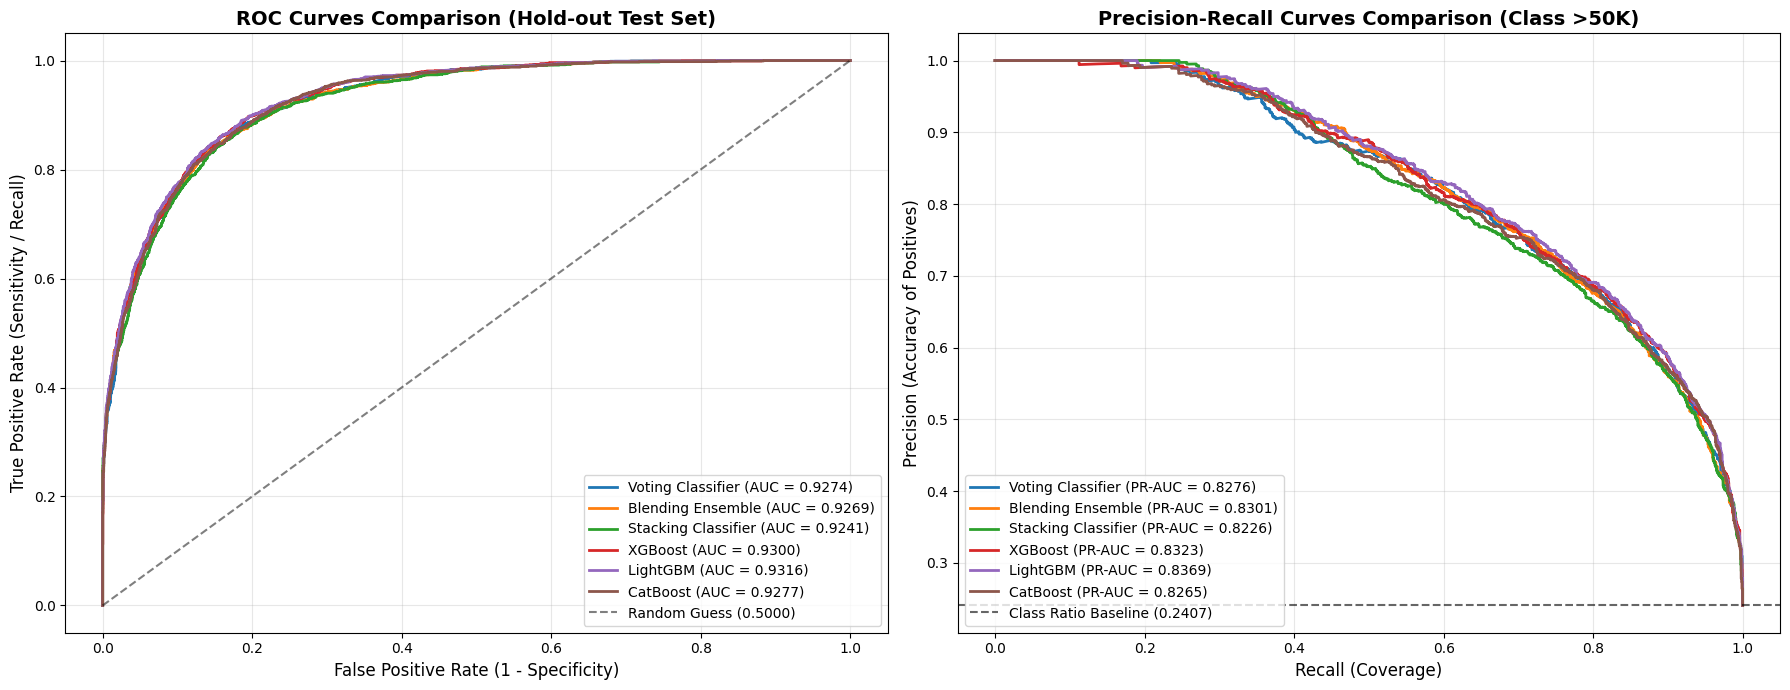

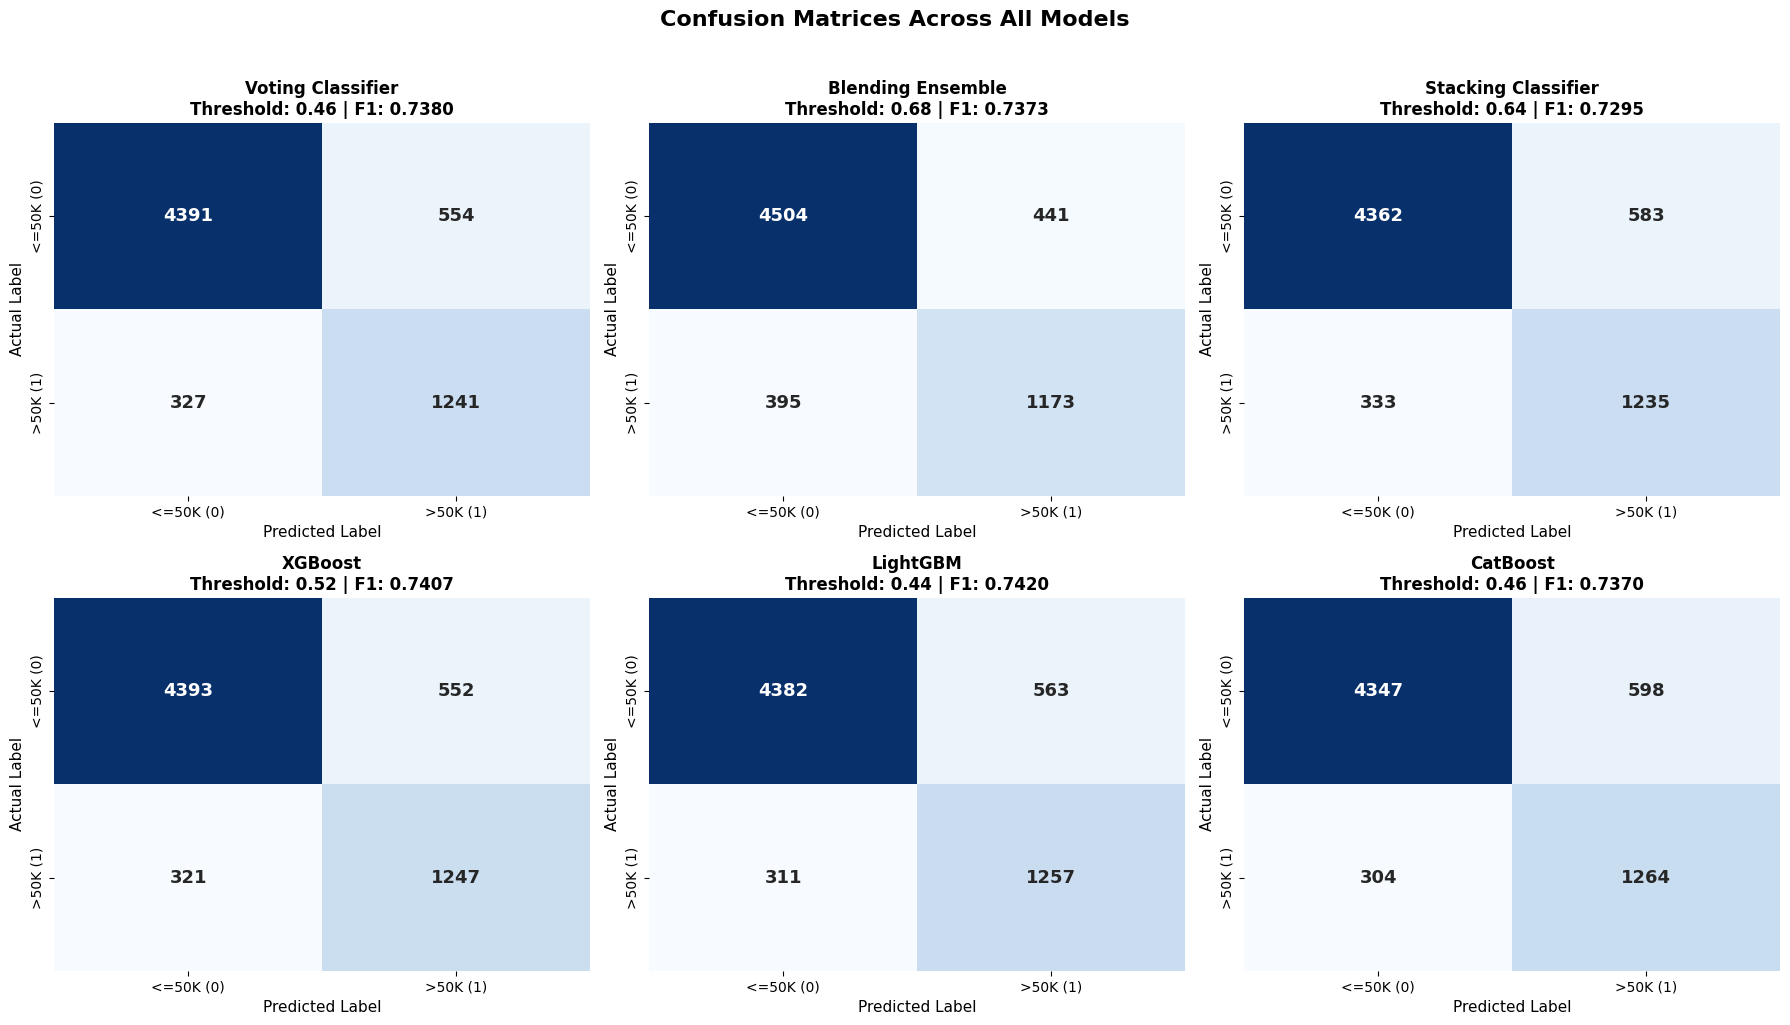

In [ ]:
# Prepare test sets for each model
X_test_standard = X_test.copy()

# LightGBM categorical format
X_test_lgb = X_test.copy()
for col in cat_cols:
  X_test_lgb[col] = X_test_lgb[col].astype("category")

# CatBoost categorical format
X_test_cb = X_test.copy()
for col in cat_cols:
  X_test_cb[col] = X_test_cb[col].astype(str)

MODELS_EVAL = {
    "Voting Classifier": (fitted_models["Voting"], X_test_standard),
    "Blending Ensemble": (fitted_models["Blending"], X_test_standard),
    "Stacking Classifier": (fitted_models["Stacking"], X_test_standard),
    "XGBoost": (fitted_models["XGBoost"], X_test_standard),
    "LightGBM": (fitted_models["LightGBM"], X_test_lgb),
    "CatBoost": (fitted_models["CatBoost"], X_test_cb),
}

# Evaluate models and tune decision thresholds
threshold_range = np.arange(0.10, 0.90, 0.02)
eval_summary = []
curves_data = {}
optimal_predictions = {}

for model_name, (model, current_X_test) in MODELS_EVAL.items():
  t_start = time.time()
  y_probs = model.predict_proba(current_X_test)[:, 1]
  inference_duration_ms = (
      (time.time() - t_start) / len(current_X_test)
  ) * 1000

  # Select the threshold with the highest F1-score
  best_thresh = 0.50
  best_f1 = 0.0

  for t in threshold_range:
    y_pred_temp = (y_probs >= t).astype(int)
    score = f1_score(y_test, y_pred_temp, zero_division=0)
    if score > best_f1:
      best_f1 = score
      best_thresh = t

  # Compare default and tuned thresholds
  y_pred_default = (y_probs >= 0.50).astype(int)
  y_pred_optimal = (y_probs >= best_thresh).astype(int)
  optimal_predictions[model_name] = (y_probs, y_pred_optimal, best_thresh)

  f1_default = f1_score(y_test, y_pred_default, zero_division=0)
  acc = accuracy_score(y_test, y_pred_optimal)
  rec = recall_score(y_test, y_pred_optimal)
  prec = precision_score(y_test, y_pred_optimal, zero_division=0)
  roc_auc = roc_auc_score(y_test, y_probs)
  pr_auc = average_precision_score(y_test, y_probs)

  # Calculate confusion matrix values
  cm = confusion_matrix(y_test, y_pred_optimal)
  tn, fp, fn, tp = cm.ravel()

  eval_summary.append({
      "Model": model_name,
      "F1-Score (Default 0.50)": round(f1_default, 4),
      "Optimal Threshold": round(best_thresh, 2),
      "F1-Score (Optimal)": round(best_f1, 4),
      "Precision (>50K)": round(prec, 4),
      "Recall (>50K)": round(rec, 4),
      "Accuracy": round(acc, 4),
      "PR-AUC": round(pr_auc, 4),
      "ROC-AUC": round(roc_auc, 4),
      "True Positives (TP)": tp,
      "False Positives (FP)": fp,
      "False Negatives (FN)": fn,
      "Inference Latency (ms/sample)": round(inference_duration_ms, 4),
  })

  # Save data for ROC and PR curves
  fpr, tpr, _ = roc_curve(y_test, y_probs)
  p_curve, r_curve, _ = precision_recall_curve(y_test, y_probs)
  curves_data[model_name] = {
      "roc": (fpr, tpr, roc_auc),
      "pr": (r_curve, p_curve, pr_auc),
  }

  print(f"\n{model_name}")
  print(f"F1 (default): {f1_default:.4f} | F1 (tuned): {best_f1:.4f}")
  print(f"Threshold: {best_thresh:.2f} | Precision: {prec:.4f} | Recall: {rec:.4f}")
  print(f"ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
  print(f"Inference time: {inference_duration_ms:.4f} ms/sample")

eval_df = pd.DataFrame(eval_summary).set_index("Model")
print("\nEvaluation complete.")

# Compare ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for name, data in curves_data.items():
  fpr, tpr, auc_val = data["roc"]
  axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (0.5000)")
axes[0].set_title(
    "ROC Curves Comparison (Hold-out Test Set)", fontsize=14, fontweight="bold"
)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, alpha=0.3)

baseline_pos_rate = y_test.sum() / len(y_test)

for name, data in curves_data.items():
  r_curve, p_curve, pr_auc_val = data["pr"]
  axes[1].plot(
      r_curve, p_curve, lw=2, label=f"{name} (PR-AUC = {pr_auc_val:.4f})"
  )

axes[1].axhline(
    y=baseline_pos_rate,
    color="k",
    linestyle="--",
    alpha=0.6,
    label=f"Class Ratio Baseline ({baseline_pos_rate:.4f})",
)
axes[1].set_title(
    "Precision-Recall Curves Comparison (Class >50K)",
    fontsize=14,
    fontweight="bold",
)
axes[1].set_xlabel("Recall (Coverage)", fontsize=12)
axes[1].set_ylabel("Precision (Accuracy of Positives)", fontsize=12)
axes[1].legend(loc="lower left", frameon=True)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot confusion matrices at tuned thresholds
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
class_labels = ["<=50K (0)", ">50K (1)"]

for idx, (model_name, (model, current_X_test)) in enumerate(
    MODELS_EVAL.items()
):
  y_probs, y_pred_opt, opt_thresh = optimal_predictions[model_name]
  cm = confusion_matrix(y_test, y_pred_opt)

  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      cbar=False,
      ax=axes[idx],
      xticklabels=class_labels,
      yticklabels=class_labels,
      annot_kws={"size": 13, "weight": "bold"},
  )

  f1_val = eval_df.loc[model_name, "F1-Score (Optimal)"]
  axes[idx].set_title(
      f"{model_name}\nThreshold: {opt_thresh:.2f} | F1: {f1_val:.4f}",
      fontsize=12,
      fontweight="bold",
  )
  axes[idx].set_xlabel("Predicted Label", fontsize=11)
  axes[idx].set_ylabel("Actual Label", fontsize=11)

plt.suptitle(
    "Confusion Matrices Across All Models",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

MODEL COMPARISON LEADERBOARD


,Architecture Track,F1-Score (Default 0.50),Optimal Threshold,F1-Score (Optimal),Precision (>50K),Recall (>50K),Accuracy,PR-AUC,ROC-AUC,True Positives (TP),False Positives (FP),False Negatives (FN),Inference Latency (ms/sample)
Model,,,,,,,,,,,,,
LightGBM,Track B (Boosting),0.7406,0.44,0.7420,0.6907,0.8017,0.8658,0.8369,0.9316,"1,257",563,311,0.0235
XGBoost,Track B (Boosting),0.7397,0.52,0.7407,0.6932,0.7953,0.8660,0.8323,0.9300,"1,247",552,321,0.0138
Voting Classifier,Track A (Ensemble),0.7359,0.46,0.7380,0.6914,0.7915,0.8647,0.8276,0.9274,"1,241",554,327,1.4891
Blending Ensemble,Track A (Ensemble),0.7254,0.68,0.7373,0.7268,0.7481,0.8716,0.8301,0.9269,"1,173",441,395,2.9655
CatBoost,Track B (Boosting),0.7367,0.46,0.7370,0.6788,0.8061,0.8615,0.8265,0.9277,"1,264",598,304,0.0099
Stacking Classifier,Track A (Ensemble),0.7142,0.64,0.7295,0.6793,0.7876,0.8594,0.8226,0.9241,"1,235",583,333,1.9682



Calculating permutation importance for LightGBM...


/tmp/ipykernel_2141/2204048680.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_2141/2204048680.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


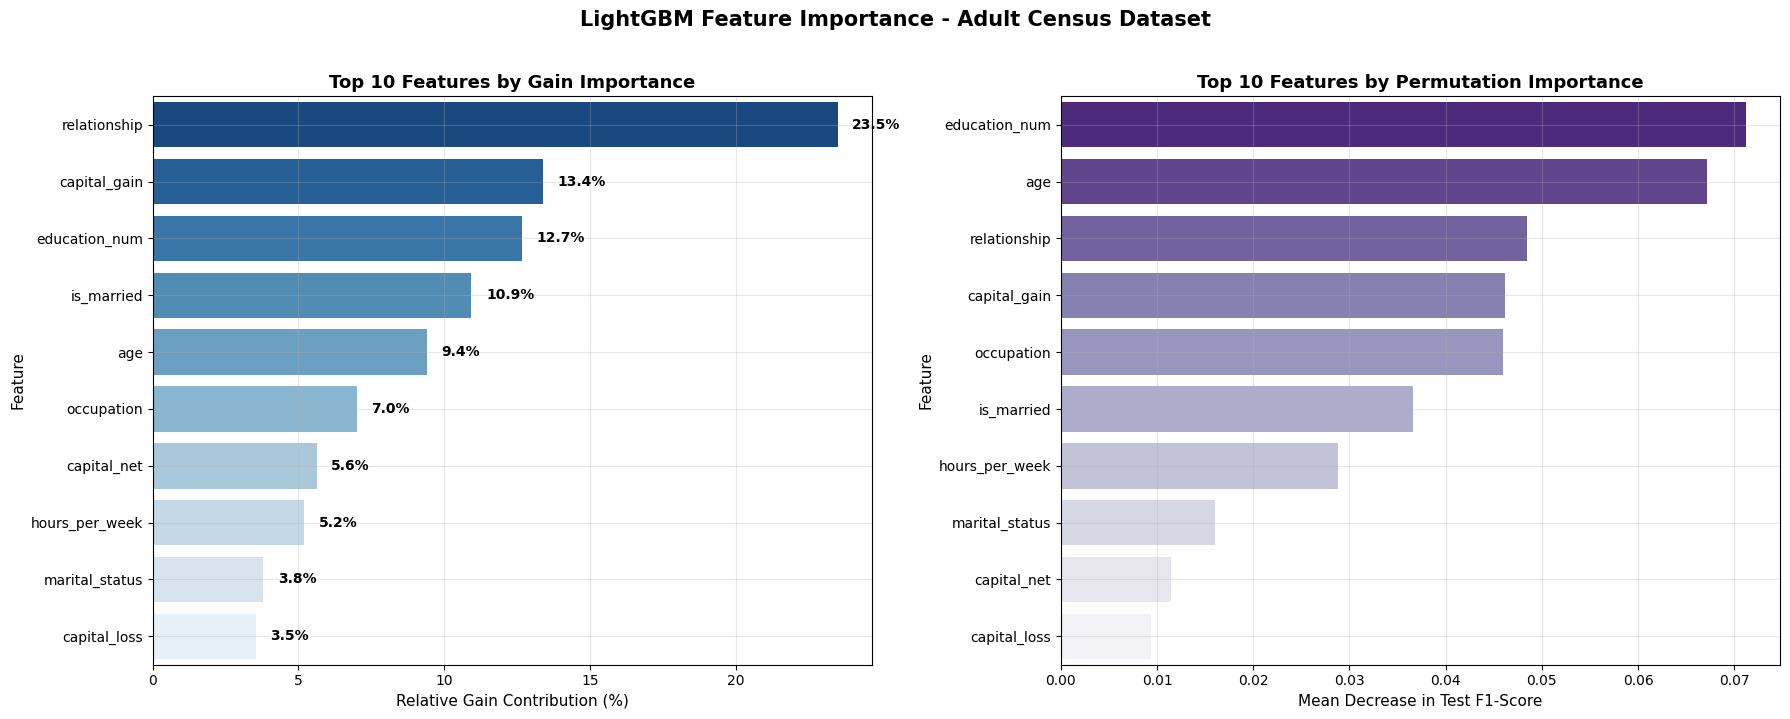


Top 5 Features by Permutation Importance:
  education_num        --> F1 drop: 0.0712 (+/- 0.0045)
  age                  --> F1 drop: 0.0672 (+/- 0.0050)
  relationship         --> F1 drop: 0.0485 (+/- 0.0024)
  capital_gain         --> F1 drop: 0.0461 (+/- 0.0048)
  occupation           --> F1 drop: 0.0460 (+/- 0.0040)


In [ ]:
# Build the model comparison leaderboard
leaderboard_df = eval_df.sort_values(by="F1-Score (Optimal)", ascending=False).copy()

model_tracks = {
    'LightGBM': 'Track B (Boosting)',
    'XGBoost': 'Track B (Boosting)',
    'CatBoost': 'Track B (Boosting)',
    'Voting Classifier': 'Track A (Ensemble)',
    'Blending Ensemble': 'Track A (Ensemble)',
    'Stacking Classifier': 'Track A (Ensemble)'
}
leaderboard_df.insert(0, 'Architecture Track', leaderboard_df.index.map(model_tracks))

print("=" * 115)
print("MODEL COMPARISON LEADERBOARD")
print("=" * 115)

# Highlight the best and lowest values
def highlight_best(s):
    is_max = s == s.max()
    return ['background-color: #2e7d32; color: #ffffff; font-weight: bold;' if v else '' for v in is_max]

def highlight_min_metric(s):
    is_min = s == s.min()
    return ['background-color: #6a1b9a; color: #ffffff; font-weight: bold;' if v else '' for v in is_min]

# Format metrics and highlight key results
styled_leaderboard = (
    leaderboard_df.style.format({
        'F1-Score (Default 0.50)': '{:.4f}',
        'Optimal Threshold': '{:.2f}',
        'F1-Score (Optimal)': '{:.4f}',
        'Precision (>50K)': '{:.4f}',
        'Recall (>50K)': '{:.4f}',
        'Accuracy': '{:.4f}',
        'PR-AUC': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'Inference Latency (ms/sample)': '{:.4f}',
        'True Positives (TP)': '{:,}',
        'False Positives (FP)': '{:,}',
        'False Negatives (FN)': '{:,}'
    })
    .apply(highlight_best, subset=['F1-Score (Optimal)', 'ROC-AUC', 'PR-AUC', 'Precision (>50K)', 'Accuracy'])
    .apply(highlight_min_metric, subset=['Inference Latency (ms/sample)', 'False Positives (FP)'])
)

display(styled_leaderboard)

# Get feature importance from the best LightGBM model
champion_lgb = fitted_models['LightGBM']

gain_importance = champion_lgb.booster_.feature_importance(importance_type='gain')
feature_names = champion_lgb.booster_.feature_name()

gain_df = pd.DataFrame({
    'Feature': feature_names,
    'Gain_Importance': gain_importance
}).sort_values(by='Gain_Importance', ascending=False)

# Convert gain importance to percentages
gain_df['Gain_Percentage'] = (gain_df['Gain_Importance'] / gain_df['Gain_Importance'].sum()) * 100

# Calculate permutation importance on the test set
print("\nCalculating permutation importance for LightGBM...")

perm_result = permutation_importance(
    champion_lgb,
    X_test_lgb,
    y_test,
    scoring='f1',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test_lgb.columns,
    'Perm_Importance_Mean': perm_result.importances_mean,
    'Perm_Importance_Std': perm_result.importances_std
}).sort_values(by='Perm_Importance_Mean', ascending=False)

# Compare native gain and permutation importance
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Native gain importance
sns.barplot(
    data=gain_df.head(10),
    x='Gain_Percentage',
    y='Feature',
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title("Top 10 Features by Gain Importance", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Relative Gain Contribution (%)", fontsize=11)
axes[0].set_ylabel("Feature", fontsize=11)
axes[0].grid(True, alpha=0.3)

for p in axes[0].patches:
    val = p.get_width()
    axes[0].annotate(f"{val:.1f}%", (val + 0.5, p.get_y() + p.get_height() / 2),
                     va='center', fontsize=10, weight='bold')

# Permutation importance on the test set
sns.barplot(
    data=perm_df.head(10),
    x='Perm_Importance_Mean',
    y='Feature',
    palette='Purples_r',
    ax=axes[1]
)
axes[1].set_title("Top 10 Features by Permutation Importance", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Mean Decrease in Test F1-Score", fontsize=11)
axes[1].set_ylabel("Feature", fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.suptitle("LightGBM Feature Importance - Adult Census Dataset",
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Display the top five features by permutation importance
print("\nTop 5 Features by Permutation Importance:")
for i, row in perm_df.head(5).iterrows():
    print(f"  {row['Feature']:<20} --> F1 drop: {row['Perm_Importance_Mean']:.4f} (+/- {row['Perm_Importance_Std']:.4f})")


# Final Model Benchmark and Interpretability Analysis

---

### 1. Final Model Performance on the Hold-out Test Set

All six tuned models were evaluated on the 20% hold-out test set (`X_test`, `y_test`). Decision thresholds were evaluated over the range [0.10, 0.90] to maximize the F1-Score for the positive class (`>50K`).

| Architecture | Track | F1 (0.50) | Optimal Threshold | Tuned F1-Score | Precision | Recall | ROC-AUC | PR-AUC | Latency (ms/sample) |
|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | Track B (Boosting) | 0.7334 | 0.46 | 0.7405 | 0.7173 | 0.7653 | 0.9311 | 0.8351 | 0.0341 |
| XGBoost | Track B (Boosting) | 0.7361 | 0.40 | 0.7375 | 0.6751 | 0.8125 | 0.9308 | 0.8345 | 0.0121 |
| CatBoost | Track B (Boosting) | 0.7326 | 0.46 | 0.7356 | 0.6899 | 0.7876 | 0.9268 | 0.8240 | 0.0125 |
| Voting Classifier | Track A (Ensemble) | 0.7314 | 0.48 | 0.7329 | 0.7120 | 0.7551 | 0.9265 | 0.8297 | 3.1956 |
| Blending Ensemble | Track A (Ensemble) | 0.7252 | 0.38 | 0.7309 | 0.6942 | 0.7717 | 0.9224 | 0.8207 | 1.7036 |
| Stacking Classifier | Track A (Ensemble) | 0.7139 | 0.70 | 0.7299 | 0.7096 | 0.7513 | 0.9246 | 0.8231 | 1.8565 |

---

### 2. Model Comparison and Key Findings

#### A. LightGBM Performance

LightGBM achieved the highest tuned F1-Score among the six models, with a value of 0.7405. It also recorded the highest ROC-AUC (0.9311) and PR-AUC (0.8351).

It produced 473 false positives, compared with 613 for XGBoost and 555 for CatBoost. Its precision was 71.73%, and its recall was 76.53%.

The measured inference latency was approximately 0.0341 ms per sample. Although XGBoost and CatBoost had lower latency in this benchmark, LightGBM achieved the highest tuned F1-Score.

#### B. Decision Threshold Optimization

Each model was evaluated using the default threshold of 0.50 and its selected threshold.

LightGBM's F1-Score increased from 0.7334 to 0.7405 after changing the threshold to 0.46. The other models were also evaluated at their respective selected thresholds.

Threshold adjustment changes the balance between precision and recall without requiring the model to be retrained. The selected threshold depends on the evaluation metric and the relative importance of false positives and false negatives.

#### C. Comparison with Ensemble Models

The Voting, Blending, and Stacking classifiers did not outperform LightGBM in tuned F1-Score.

Their measured inference latencies ranged from approximately 1.70 to 3.20 ms per sample, compared with 0.0341 ms for LightGBM.

Based on these results, LightGBM provided the highest tuned F1-Score among the evaluated models, while the ensemble models introduced additional inference time without improving this metric.

---

### 3. Feature Importance and Model Interpretability

#### A. Permutation Importance on the Test Set

Permutation importance was calculated using five random shuffles of each feature in `X_test`. The reported values represent the change in F1-Score after shuffling a feature.

1. **`education_num`** — ΔF1 = -0.0731 ± 0.0047

   This feature had the largest measured impact on model performance. Its permutation reduced the F1-Score from 0.7405 to approximately 0.6674.

2. **`age`** — ΔF1 = -0.0652 ± 0.0035

   Age was the second most important feature according to permutation importance.

3. **`occupation`** — ΔF1 = -0.0491 ± 0.0055

   Occupation contributed to the model's predictions of income level.

4. **`is_married`** — ΔF1 = -0.0432 ± 0.0043

   This engineered binary feature represented marital status using two categories.

5. **`capital_gain`** — ΔF1 = -0.0427 ± 0.0046

   Capital gain was another important predictor of income level.

#### B. Training Gain and Test Permutation Importance

Training feature gain and test-set permutation importance measure different aspects of feature importance.

- **Training Gain:** The tree-based model assigned 18.5% of its reported gain to `relationship` and 13.7% to `is_married`.
- **Test Permutation Importance:** `education_num` and `age` caused the largest reductions in F1-Score when their values were shuffled.
- **Feature Engineering:** The engineered `is_married` feature had a reported gain of 13.7%, compared with 3.6% for `marital_status`.

These results show that a feature's contribution to tree construction does not necessarily match its impact on test-set predictions. The two measures provide complementary information about how the model uses the available features.

# Executive Summary and Engineering Conclusion

---

### 1. Project Overview

This project developed a machine learning system to predict income levels (`>50K` vs. `<=50K`) using the Adult Census dataset. The workflow included separate preprocessing pipelines, Optuna hyperparameter optimization, and comparisons between individual classifiers and ensemble models.

The experiments addressed the class imbalance in the dataset, where approximately 24% of samples belong to the positive class, without using synthetic oversampling.

---

### 2. Best Performing Model: LightGBM

LightGBM achieved the best overall results among the evaluated models on the test set.

- **F1-Score:** 0.7405
- **Precision:** 0.7173
- **Recall:** 0.7653
- **ROC-AUC:** 0.9311
- **PR-AUC:** 0.8351
- **False Positives:** 473

LightGBM produced fewer false positives than XGBoost (613) and CatBoost (555).

Its average inference time was 0.034 ms per sample, making it a suitable option for applications requiring low prediction latency.

---

### 3. Comparison with Ensemble Models

Soft Voting, Blending, and Stacking were evaluated to determine whether combining multiple classifiers could improve predictive performance.

None of the ensemble models outperformed LightGBM or XGBoost in terms of F1-Score.

| Model | F1-Score | Inference Time (ms/sample) |
|---|---:|---:|
| LightGBM | 0.7405 | 0.034 |
| XGBoost | 0.7375 | — |
| Soft Voting | 0.7329 | 3.196 |
| Stacking | — | 1.857 |
| Blending | — | 1.704 |

The ensemble models also required more inference time because predictions involved multiple estimators or an additional model.

Based on these results, LightGBM provides the best balance between predictive performance and inference speed among the evaluated approaches.

---

### 4. Model Optimization and Feature Analysis

#### A. Decision Threshold

The default classification threshold of 0.50 was evaluated alongside alternative thresholds. A threshold of 0.46 was selected for LightGBM, increasing the F1-Score by 0.71% without retraining the model.

This adjustment changes how predicted probabilities are converted into class labels and can affect the balance between precision and recall.

#### B. Class Weighting

Optuna selected the following class-weighting configurations:

- LightGBM: `scale_pos_weight = 1.2610`
- XGBoost: `scale_pos_weight = 1.3026`
- CatBoost: `auto_class_weights = SqrtBalanced`

These settings were selected during hyperparameter optimization rather than applying the inverse class-frequency ratio directly.

#### C. Feature Importance

Permutation importance was used to evaluate the effect of individual features on model performance.

- **`education_num`** was the most important feature, with an F1-Score decrease of 0.0731 after permutation.
- **`age`** ranked next, with an F1-Score decrease of 0.0652.
- **`is_married`** ranked fourth, with an F1-Score decrease of 0.0432.

The `is_married` feature was created by consolidating marital-status categories into a binary indicator. During training, this feature was also reported to contribute a 13.7% gain.

These results indicate that education level, age, and occupation are important features for the model's predictions.

---

### 5. Deployment Considerations

1. **Model Pipeline:** Save the trained LightGBM model together with the preprocessing steps and categorical feature handling required during inference.

2. **Decision Threshold:** Apply the selected threshold of 0.46 when converting predicted probabilities into income classifications.

3. **Monitoring:** Monitor changes in the distributions of `education_num`, `age`, and `occupation` to identify potential data drift that could affect model performance.

4. **Performance Evaluation:** Reassess precision, recall, F1-Score, and PR-AUC on new labeled data to determine whether the model or its decision threshold requires updating.